# Café Data Analysis
On this notebook we will be analysing the data collected by a Café over a period of a year.


## Table of Contents
- [Part 1 - EDA](#part-1)
  - [Step 1 - Setup and Questions](#step-1)
    - [Step 1.1 - Immediate questions we would like to see answered](#step-1-1)
    - [Step 1.2 - Libraries and modules](#step-1-2)
  - [Step 2 - Basic Inspection](#step-2)
    - [Step 2.1 - Loading the data](#step-2-1)
    - [Step 2.2 - Dataset size](#step-2-2)
    - [Step 2.3 - Column types](#step-2-3)
    - [Step 2.4 - Unique values](#step-2-4)
    - [Step 2.5 - Summary statistics](#step-2-5)
  - [Step 3 - Data Cleaning and Preparation](#step-3)
    - [Step 3.1 - Missing values](#step-3-1)
    - [Step 3.2 - Text formatting and type conversion](#step-3-2)
    - [Step 3.3 - Duplicate detection](#step-3-3)
    - [Step 3.4 - Fixing item names](#step-3-4)
    - [Step 3.5 - Fixing categories](#step-3-5)
    - [Step 3.6 - Aggregating by order](#step-3-6)
  - [Step 4 - Descriptive Statistics](#step-4)
    - [Step 4.1 - Headline figures](#step-4-1)
    - [Step 4.2 - Measures of center and spread](#step-4-2)
    - [Step 4.3 - Distribution shapes](#step-4-3)
    - [Step 4.4 - Most sold products](#step-4-4)
    - [Step 4.5 - Most sold categories](#step-4-5)
    - [Step 4.6 - Most sold products per category](#step-4-6)
  - [Step 5 - Time Series Analysis and Sales Trend Investigation](#step-5)
    - [Step 5.1 - Trend isolation](#step-5-1)
    - [Step 5.2 - Structural decomposition](#step-5-2)
    - [Step 5.3 - Seasonality and recurring cycles](#step-5-3)
    - [Step 5.4 - Detrending and stationarity](#step-5-4)
    - [Step 5.5 - Key takeaways](#step-5-5)
  - [Step 6 - Category Performance and Relationship Discovery](#step-6)
    - [Step 6.1 - Category performance](#step-6-1)
    - [Step 6.2 - Concentration of sales (Pareto)](#step-6-2)
    - [Step 6.3 - Category mix through the day and the week](#step-6-3)
    - [Step 6.4 - Most sold products per month and season](#step-6-4)
    - [Step 6.5 - Relationships](#step-6-5)
    - [Step 6.6 - Anomalies](#step-6-6)
    - [Step 6.7 - Statistical tests](#step-6-7)
    - [Step 6.8 - Key takeaways](#step-6-8)
  - [Step 7 - Offensive Data Preparation & Feature Engineering](#step-7)
    - [Step 7.1 - Promotion and base product](#step-7-1)
    - [Step 7.2 - Time, drink and bill features](#step-7-2)
    - [Step 7.3 - Order-level features](#step-7-3)
  - [Step 8 - Data Storytelling and Business Synthesis](#step-8)

<a id="part-1"></a>
## Part 1 - EDA

<a id="step-1"></a>
### Step 1 - Setup and Questions
Our task is to explore the data, identify interesting patterns and develop insights to help the business improve its performance, but what does this mean?

<a id="step-1-1"></a>
#### Step 1.1 - Immediate questions we would like to see answered
- What are the most sold products in total? *(Step 4)*
- What is the income in total? *(Step 4)*
- What are the most sold products per month? *(Step 6)*
- What are the most sold products per week (including day / histogram)? *(Step 5 weekly cycle, Step 6)*
- What products are usually bought together (see per day, per week, per month)? *(Part 2)*
- What are the most sold products per quarter (each 3 months or per season)? *(Step 6)*
- ~~Do products with discount end up giving more profit?~~ The data has **no costs**, so we can't calculate profit. We look at revenue instead: *do products on promotion bring in more revenue?* *(Step 7 promo column, Part 3)*

<a id="step-1-2"></a>
#### Step 1.2 - Libraries and modules
The calculations for each step live in separate Python files (`cleaning.py`, `descriptive.py`, `time_series.py`, `categories.py`, `features.py`), so this notebook only shows the results and what they mean.

In [53]:
# Libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Light gray grid behind every plot (axisbelow keeps it under the bars and lines)
plt.rcParams.update({"axes.grid": True, "grid.color": "lightgray", "grid.linewidth": 0.6, "axes.axisbelow": True})

# Our own modules: the calculations for each step
import cleaning as cl       # Steps 2-3
import descriptive as ds    # Step 4
import time_series as ts    # Step 5
import categories as cat    # Step 6
import features as fe       # Step 7

<a id="step-2"></a>
### Step 2 - Basic Inspection
A first look at the raw data: its shape, column types, unique values and summary statistics.

<a id="step-2-1"></a>
#### Step 2.1 - Loading the data

In [54]:
# Import and inspect (the file is not UTF-8, so it is read as latin-1, see cleaning.load_raw)
df_original = cl.load_raw("cafe.csv")
df_original.head()

,Date,Bill Number,Item Desc,Time,Quantity,Rate,Tax,Discount,Total,Category
0,1-Apr-10,G0470115,QUA MINERAL WATER(1000ML),13:15:11,1,50,"11,88",0,"61,88",BEVERAGE
1,1-Apr-10,G0470115,MONSOON MALABAR (AULAIT),13:15:11,1,100,"23,75",0,"123,75",BEVERAGE
2,1-Apr-10,G0470116,MASALA CHAI CUTTING,13:17:35,1,40,"9,5",0,"49,5",BEVERAGE
3,1-Apr-10,G0470117,QUA MINERAL WATER(1000ML),13:19:55,1,50,"11,88",0,"61,88",BEVERAGE
4,1-Apr-10,G0470283,MOROCCAN MINT TEA,01:20:18,1,45,"10,69",0,"55,69",BEVERAGE


<a id="step-2-2"></a>
#### Step 2.2 - Dataset size

In [55]:
df_original.shape

(145830, 10)

The dataset contains 145_830 rows and 10 columns.

<a id="step-2-3"></a>
#### Step 2.3 - Column types

In [56]:
df_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 145830 entries, 0 to 145829
Data columns (total 10 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   Date          145830 non-null  str  
 1   Bill Number   145830 non-null  str  
 2   Item Desc     145830 non-null  str  
 3   Time          145830 non-null  str  
 4   Quantity      145830 non-null  int64
 5   Rate          145830 non-null  str  
 6   Tax           145830 non-null  str  
 7   Discount      145830 non-null  str  
 8   Total         145830 non-null  str  
 9   Category      145830 non-null  str  
dtypes: int64(1), str(9)
memory usage: 11.1 MB


Here we noticed that the rate, tax, discount and total were strings instead of floats (because it's money), and that the date and time are also strings instead of datetimes.

Another thing is that there is a column called category which can be used to categorize the data.

<a id="step-2-4"></a>
#### Step 2.4 - Unique values

In [57]:
df_original.nunique()

Date              365
Bill Number     69982
Item Desc         580
Time            36200
Quantity           20
Rate              134
Tax               445
Discount          111
Total             470
Category            9
dtype: int64

This shows us the 365 dates (days) and 9 different categories.

<a id="step-2-5"></a>
#### Step 2.5 - Summary statistics

In [58]:
df_original.describe()

,Quantity
count,145830.000000
mean,1.121299
std,0.477237
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,30.000000


Describe only shows Quantity, since like mentioned before, columns that should be floats, aren't. This step will be repeated later.

These columns will be transformed into the right type in the data cleaning step.

<a id="step-3"></a>
### Step 3 - Data Cleaning and Preparation
Before analysing the data we clean it, step by step:
- **3.1** Check for missing values
- **3.2** Fix the text formatting and convert columns to the right types
- **3.3** Detect duplicate rows
- **3.4** Fix broken item names and different names for the same product
- **3.5** Fix products filed in the wrong category
- **3.6** Merge repeated items in the same order and build one row per order

From this point onwards we save a copy of the dataset so we won't touch the raw data.

In [59]:
# Save a copy of the dataset to work with instead of the raw data.
df_copy = df_original.copy()
df_copy.to_csv("data_copy.csv", index=False)

<a id="step-3-1"></a>
#### Step 3.1 - Missing values

Next we decided to see if there are any missing values and think on how to handle them

In [60]:
df_copy.isnull().sum()

Date            0
Bill Number     0
Item Desc       0
Time            0
Quantity        0
Rate            0
Tax             0
Discount        0
Total           0
Category        0
dtype: int64

The dataset doesn't contain any missing values, this step can be safely skipped.

<a id="step-3-2"></a>
#### Step 3.2 - Text formatting and type conversion

Two formatting problems:
- **Extra spaces**: the column `Bill Number ` and the category `LIQUOR ` have a trailing space. Because of that, pandas sees "LIQUOR " and "LIQUOR" as **two different categories**. We remove leading and trailing spaces from the column names and text columns.
- **Wrong types**: the money columns use `,` instead of `.` as decimal separator, so Python reads them as text. We convert them to numbers, and the date to a real date.

In [61]:
df_copy = cl.strip_text(df_copy)
df_copy = cl.convert_types(df_copy)
print("Categories:", sorted(df_copy["Category"].unique()))
df_copy.dtypes

Categories: ['BEVERAGE', 'FOOD', 'LIQUOR', 'LIQUOR & TPBACCO', 'MERCHANDISE', 'MISC', 'TOBACCO', 'WINES']


Date           datetime64[us]
Bill Number               str
Item Desc                 str
Time                      str
Quantity                int64
Rate                  float64
Tax                   float64
Discount              float64
Total                 float64
Category                  str
dtype: object

In [62]:
df_copy.describe()

,Date,Quantity,Rate,Tax,Discount,Total
count,145830,145830.000000,145830.000000,145830.000000,145830.000000,145830.000000
mean,2010-10-04 15:52:45.126517,1.121299,161.782259,48.929061,0.095079,224.959852
min,2010-04-01 00:00:00,1.000000,0.010000,0.000000,0.000000,0.010000
25%,2010-07-10 00:00:00,1.000000,95.000000,22.560000,0.000000,117.560000
50%,2010-10-07 00:00:00,1.000000,125.000000,32.060000,0.000000,167.060000
75%,2011-01-01 00:00:00,1.000000,225.000000,72.000000,0.000000,315.000000
max,2011-03-31 00:00:00,30.000000,2100.000000,2731.250000,825.000000,14231.250000
std,NaN,0.477237,102.244631,40.272851,3.720735,164.960776


Something interesting that popped to us immediately is how the min for Rate (how much something costs before tax) is 0.01 and the max is 2100, this seems highly suspicious and flagged for later exploration, but for now let's continue exploring. *(Checked in Step 6: the 0.01 lines are a free Mother's Day item.)*

<a id="step-3-3"></a>
#### Step 3.3 - Duplicate detection
Here we check for duplicate rows and decide how to handle them.

In [63]:
print(f"Number of duplicate rows: {df_copy.duplicated().sum()}")
cl.duplicate_rows(df_copy)

Number of duplicate rows: 680


,Date,Bill Number,Item Desc,Time,Quantity,Rate,Tax,Discount,Total,Category
197,2010-04-01,G0470211,B.M.T. PANINI,19:42:27,1,105.0,24.94,0.0,129.94,FOOD
198,2010-04-01,G0470211,B.M.T. PANINI,19:42:27,1,105.0,24.94,0.0,129.94,FOOD
199,2010-04-01,G0470211,B.M.T. PANINI,19:42:27,1,105.0,24.94,0.0,129.94,FOOD
4472,2010-04-01,G0470223,ADD ON S,20:33:30,1,15.0,3.56,0.0,18.56,MISC
4473,2010-04-01,G0470223,ADD ON S,20:33:30,1,15.0,3.56,0.0,18.56,MISC
...,...,...,...,...,...,...,...,...,...,...
138712,2011-03-30,G0533709,MEZE PLATTER,22:19:39,1,150.0,35.63,0.0,185.63,FOOD
138725,2011-03-30,G0533714,MEZE PLATTER,22:32:43,1,150.0,35.63,0.0,185.63,FOOD
138726,2011-03-30,G0533714,MEZE PLATTER,22:32:43,1,150.0,35.63,0.0,185.63,FOOD
143213,2011-03-31,G0533751,SUNNY SIDEUP + BEVERAGE,11:45:56,1,99.0,23.51,0.0,122.51,FOOD


<a id="step-3-4"></a>
#### Step 3.4 - Fixing item names
While looking at the most sold products we noticed some strange item names, like `RED SANGRIA (GLS)á áááááááááá`. So we went through all 580 product names to find names that are broken, or different names for the same product. We:
- searched for characters that are not normal letters, numbers or punctuation
- compared the names after removing spaces and punctuation, and with a similarity score (`difflib`) to find almost-identical names
- for every suspicious pair, compared the **price** and the **dates** when each name was used: if one name stops being used when the other starts, and the price matches, it's most likely the same product

What we found and fix here:

| Problem | Example | Why we fix it |
|---|---|---|
| **Junk characters** at the end of 4 names | `RED SANGRIA (GLS)á ááááá`, `WHITE SANGRIA (CARAFE)áááá` | Encoding garbage from the till system, not part of the name |
| **Double spaces** in 13 names | `N R G  HOOKAH` (2,314 units) vs `N R G HOOKAH` (15 units) | The same hookah at the same price (450) was counted as 2 products |
| **Spelling typo** | `MORROCAN SOY KEBABS` (Jun-Sep 2010) vs `MOROCCAN SOY KEBABS` (Jan-Mar 2011) | Never used at the same time, so the same dish was renamed when the menu changed |
| **Same product, two names** | `STELLA ARTOIS` (4 units) vs `STELLA ARTOIS (GLS)` (30 units) | Same beer, same price (225) |

Names that only look alike were **not** merged because they are different products with different prices, e.g. glass vs bottle (`(GLS)`/`(BTL)`), sizes (`JR.`/`SR.CHL AVALANCHE`), add-ons (`ADD CHICKEN SAUSAGE` vs `CHICKEN SAUSAGE`) and promotions (`1+1 VLN CAB SAUV (GLS)`, handled in Step 7).

In [64]:
names_before = df_copy["Item Desc"].nunique()
df_copy = cl.fix_item_names(df_copy)
print(f"Unique products: {names_before} -> {df_copy['Item Desc'].nunique()}")

fixed = ["RED SANGRIA (GLS)", "RED SANGRIA (CARAFE)", "WHITE SANGRIA (GLS)", "WHITE SANGRIA (CARAFE)",
         "N R G HOOKAH", "MOROCCAN SOY KEBABS", "STELLA ARTOIS (GLS)"]
df_copy[df_copy["Item Desc"].isin(fixed)].groupby("Item Desc")["Quantity"].sum().to_frame("Units sold")

Unique products: 580 -> 577


,Units sold
Item Desc,
MOROCCAN SOY KEBABS,82
N R G HOOKAH,2329
RED SANGRIA (CARAFE),28
RED SANGRIA (GLS),111
STELLA ARTOIS (GLS),34
WHITE SANGRIA (CARAFE),6
WHITE SANGRIA (GLS),49


<a id="step-3-5"></a>
#### Step 3.5 - Fixing categories
When we looked at the best sellers per category (Step 4), some products were clearly in the wrong category, e.g. the **Great Lakes Shake was the top seller of FOOD**. So we checked the product list of every category, and every product that was booked under more than one category. What we found:

| Problem | Example | How we fix it |
|---|---|---|
| **Typo** in a category name | `LIQUOR & TPBACCO` | Renamed to `LIQUOR & TOBACCO` |
| **Same product in several categories** (22 products) | `ORANGE ARRABIATA`: 493x FOOD, 2x MISC | Use the category the product is booked under most often. Almost all of these MISC bookings are from **December 2010** |
| **Milkshakes filed as FOOD** (14 shakes, 16,170 units) | `GREAT LAKES SHAKE`, `OREO COOKIE SHAKE` | Moved to BEVERAGE, where the other shakes (`M & M SHAKE`, `STRAWBERRY LITE SHAKE`) already are |
| **Wines filed elsewhere** | Sangria and Zinzi under LIQUOR, `LATE HARVEST SULA CHENIN` under TOBACCO | Moved to WINES |
| **New December products booked as MISC** | 5 new sheeshas, `KF DRAFT MUG`, `GIN (SM)` | Moved to their real category. This was the cause of the **MISC spike in December** |
| **Hookah flavours and drinks always booked as MISC** | `ROSE FLAVORS SINGLE`, `PEACH BULL` | Moved to TOBACCO / BEVERAGE |

What stays in MISC are real extras: add-ons (`ADD ON S`, `ADD POTATO WEDGES`), party charges and a few products we can't place (`GUAVA`, `PLAIN JANE`). The combined `LIQUOR & TOBACCO` category is kept as it is, until we decide with the team how to handle it.

Moving the shakes changes the category totals a lot (BEVERAGE becomes the biggest category in units), so all the following steps use the corrected categories.

In [65]:
before = df_copy.copy()
df_copy = cl.fix_categories(df_copy)
print("Products in more than one category:", (df_copy.groupby("Item Desc")["Category"].nunique() > 1).sum())
cl.category_changes(before, df_copy)

Products in more than one category: 0


Products  Units
From             To                               
FOOD             BEVERAGE                14  16170
MISC             TOBACCO                  7    181
LIQUOR           WINES                    5     80
LIQUOR & TPBACCO LIQUOR & TOBACCO         4     63
MISC             LIQUOR                   5     57
TOBACCO          WINES                    2     37
MISC             FOOD                    17     31
                 BEVERAGE                 5     21
BEVERAGE         TOBACCO                  2     16
FOOD             WINES                    1      3
MISC             WINES                    1      1

<a id="step-3-6"></a>
#### Step 3.6 - Aggregating by order
We assumed that sometimes the waiter entered the same item several times in one bill (e.g. 3 x "panini x1" instead of "panini x3"). Here we merge those rows directly in `df_copy`, summing quantity and money, so each item appears once per order.

We also build `df_orders`: one row per order (bill), with the items bought, the total quantity and the money columns summed.

In [66]:
# Merge repeated rows of the same item in the same order into one row
rows_before = len(df_copy)
df_copy = cl.merge_repeated_items(df_copy)
print(f"Rows: {rows_before} -> {len(df_copy)} ({rows_before - len(df_copy)} rows merged)")

# One row per order (bill)
df_orders = cl.build_orders(df_copy)
df_copy[df_copy["Bill Number"] == "G0470211"]

Rows: 145830 -> 145052 (778 rows merged)


,Date,Bill Number,Item Desc,Time,Quantity,Rate,Tax,Discount,Total,Category
197,2010-04-01,G0470211,B.M.T. PANINI,19:42:27,3,105.0,74.82,0.0,389.82,FOOD
313,2010-04-01,G0470211,SAMBUCA,19:42:27,1,350.0,112.00,0.0,462.00,TOBACCO
314,2010-04-01,G0470211,CALCUTTA MINT,19:42:27,1,350.0,112.00,0.0,462.00,TOBACCO


<a id="step-4"></a>
### Step 4 - Descriptive Statistics

Here we summarise the data with numbers before looking at trends: the headline figures of the business, the centre and spread of the main variables, the shape of their distributions and the best-selling products.

We look at the data on three levels:
- **Line** (`df_copy`): one item in one order
- **Order** (`df_orders`): one bill, i.e. what a customer spends in one visit
- **Day**: the total revenue of each day

<a id="step-4-1"></a>
#### Step 4.1 - Headline figures

In [67]:
daily = ts.daily_revenue(df_copy)   # total revenue per day
n_days = len(daily)
ds.overview(df_copy, df_orders, daily)

,Value
Total revenue (incl. tax),"32,805,895.27"
Total tax,"7,135,324.90"
Total discount given,"13,865.38"
Number of orders,"69,982.00"
Items sold,"163,519.00"
Unique products,577.00
Days in the data,365.00
Average revenue per day,"89,879.17"
Average orders per day,191.73


This answers one of our questions: in one year the café made **32,805,895.27 moneys** in total, from 69,982 orders, which is around 90 thousand moneys per day.

<a id="step-4-2"></a>
#### Step 4.2 - Measures of center and spread

For each variable we calculate:
- **Centre**: mean, median and mode
- **Spread**: standard deviation, variance, range and IQR (Q3 - Q1)
- **Skewness**: how lopsided the distribution is (0 = symmetric, > 0 = long tail to the right)

In [68]:
ds.stats_table(df_copy, df_orders, daily)

,mean,median,mode,std,variance,min,max,range,Q1,Q3,IQR,skewness
Item price (Rate),161.75,125.00,245.00,102.23,1.045077e+04,0.01,2100.00,2099.99,95.00,225.00,130.00,1.57
Quantity,1.13,1.00,1.00,0.49,2.400000e-01,1.00,32.00,31.00,1.00,1.00,0.00,9.95
Total,226.17,167.06,323.40,166.97,2.787731e+04,0.01,14231.25,14231.24,117.56,315.00,197.44,7.11
Order total,468.78,391.46,297.00,348.42,1.213992e+05,1.26,14231.25,14229.99,272.25,594.00,321.75,4.37
Items per order,2.34,2.00,1.00,1.80,3.240000e+00,1.00,64.00,63.00,1.00,3.00,2.00,4.24
Daily revenue,89879.17,87034.64,47176.66,18557.71,3.443887e+08,47176.66,249995.13,202818.47,78232.06,99192.94,20960.88,2.22


Observations:
- **Every variable is right-skewed** (mean > median, positive skewness): most values are small, with a long tail of large ones.
- **A typical order** has 2 items and costs around 390 moneys (median). The mean (~470) is pulled up by a few very large bills, so the median is the better "typical" value here.
- **Most lines have quantity 1** (Q1 = Q3 = 1), people order more items rather than more of the same item.
- **Daily revenue** is the most stable variable (mean and median are close), but the max day (~250k) is almost 3x the median, worth checking which day that was in Step 5.
- The **min Rate of 0.01** flagged earlier shows up again. We checked it in Step 6: it's a free Mother's Day item, not an error.

<a id="step-4-3"></a>
#### Step 4.3 - Distribution shapes
Histograms show where most of the values are and boxplots show the outliers. The order total histogram is cut at the 99th percentile so the few very large bills don't squash the rest of the plot (the boxplot still shows them).

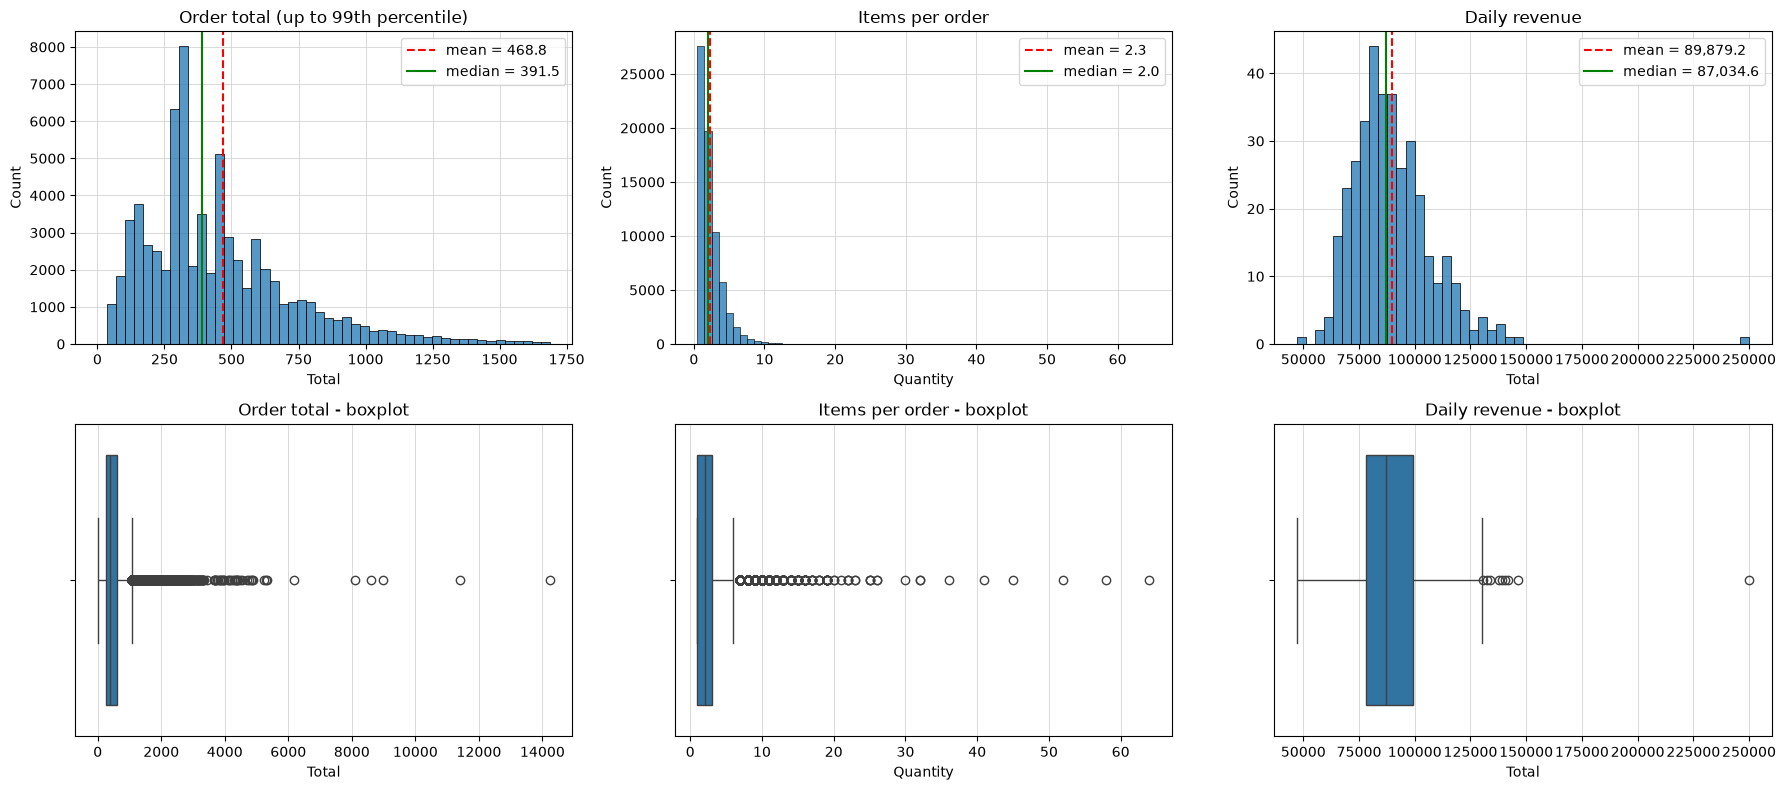

,High outliers,Share
Order total,3469,5.0%
Items per order,2051,2.9%
Daily revenue,9,2.5%


In [69]:
ds.plot_distributions(df_orders, daily)
ds.outlier_counts(df_orders, daily)

The plots confirm the skewness found above: order totals and items per order pile up on the left with a long tail of large orders, shown as many outlier points in the boxplots. These large orders are most likely groups and are real sales, so we keep them, but it's another reason to prefer the median over the mean when describing a typical customer.

<a id="step-4-4"></a>
#### Step 4.4 - Most sold products

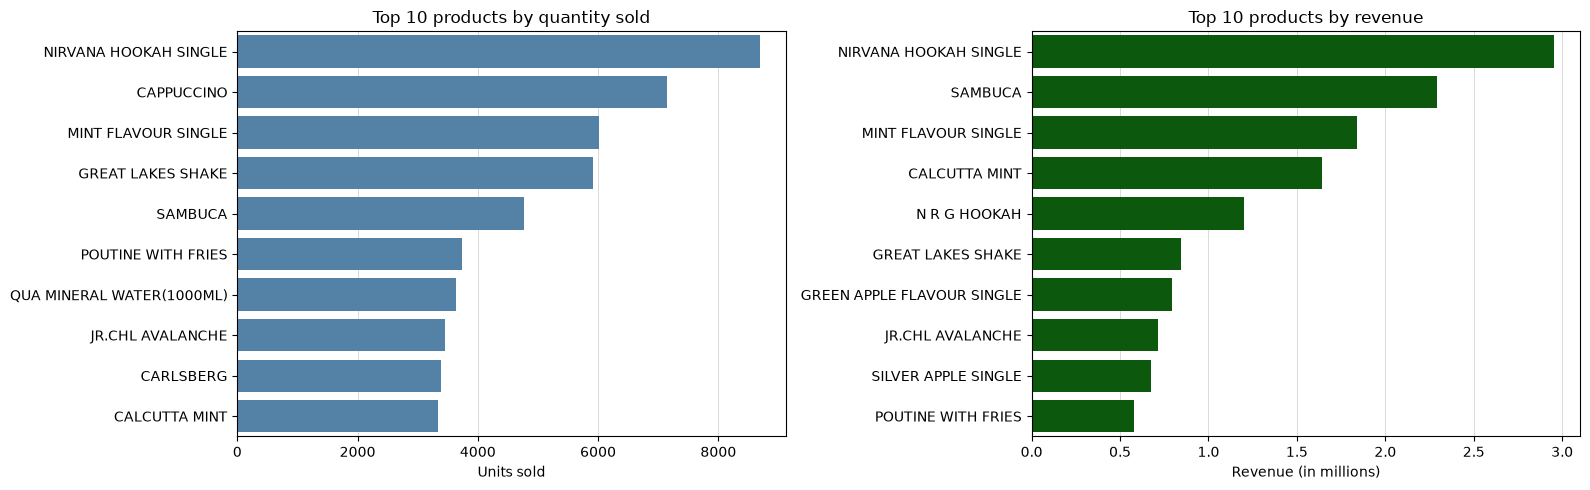

In [70]:
ds.plot_top_products(df_copy)

This answers the question of the most sold products in total. Hookahs are the café's main business: **NIRVANA HOOKAH SINGLE** is number one both in quantity and in revenue. **CAPPUCCINO** is the 2nd most sold item but, being cheap, it doesn't reach the top 5 in revenue, while **SAMBUCA** sells less but is the 2nd biggest earner. Which products drive volume and which drive money will be explored further in Step 6.

<a id="step-4-5"></a>
#### Step 4.5 - Most sold categories

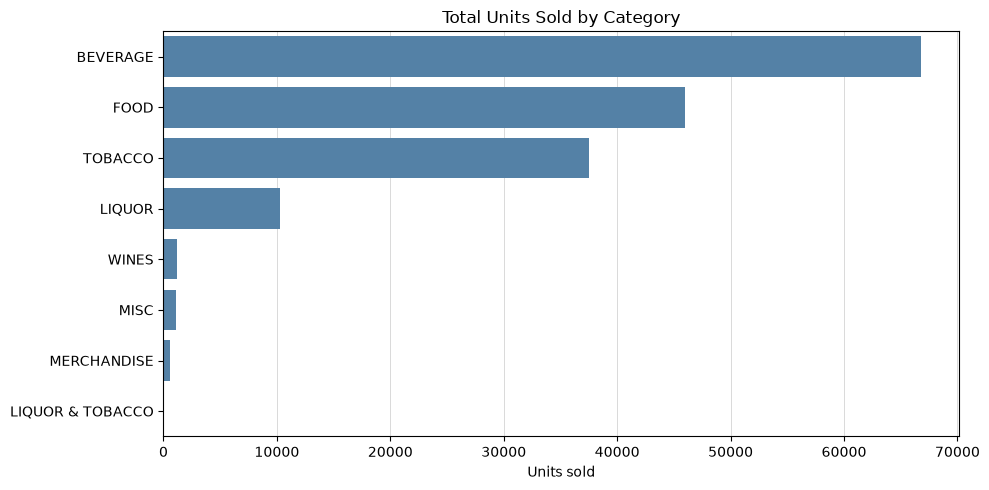

,Units sold
Category,
BEVERAGE,66812
FOOD,45999
TOBACCO,37544
LIQUOR,10261
WINES,1195
MISC,1094
MERCHANDISE,551
LIQUOR & TOBACCO,63


In [71]:
category_sales = ds.category_units(df_copy)
ds.plot_category_units(category_sales)
category_sales.to_frame("Units sold")

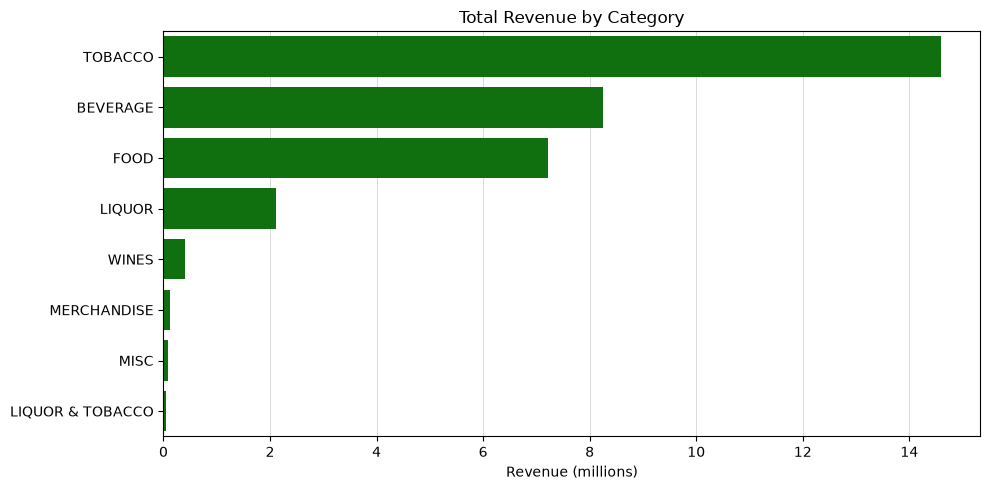

,Revenue,Share of revenue
Category,,
TOBACCO,14595948.54,44.5%
BEVERAGE,8240586.18,25.1%
FOOD,7216375.75,22.0%
LIQUOR,2106568.40,6.4%
WINES,396791.12,1.2%
MERCHANDISE,120074.02,0.4%
MISC,86989.74,0.3%
LIQUOR & TOBACCO,42561.52,0.1%


In [72]:
# Total revenue per category
category_revenue = ds.category_revenue(df_copy)
ds.plot_category_revenue(category_revenue)
category_revenue

The ranking by revenue is very different from the ranking by units:
- **Tobacco (hookah) brings in the most money**: 14.6M, **44.5%** of the revenue, while it's only 3rd in units sold.
- **Beverage** is 1st in units but 2nd in revenue (25.1%): drinks are cheap. **Food** follows closely with 22.0%.
- Tobacco, beverage and food together make **over 91%** of the revenue. Liquor adds 6.4%, and the other categories together make less than 2%.

We look at why in Step 6.1 (revenue per unit per category).

<a id="step-4-6"></a>
#### Step 4.6 - Most sold products per category

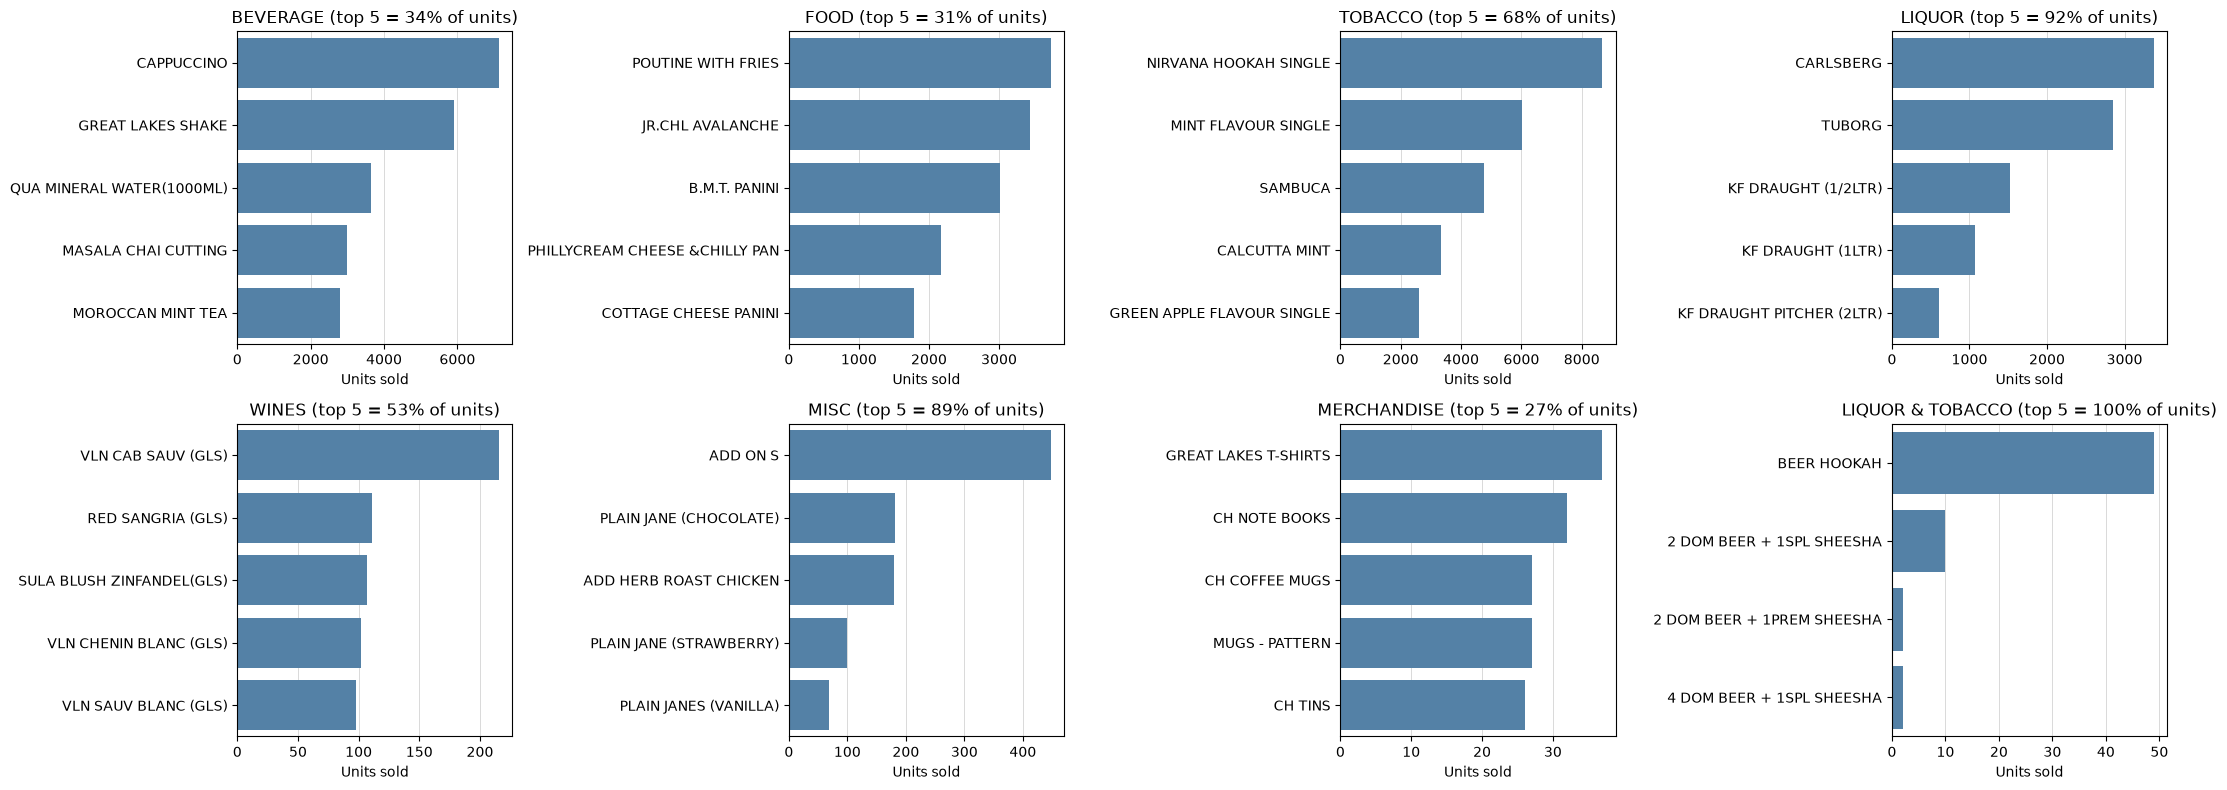

In [73]:
ds.plot_top_per_category(df_copy, category_sales)

- **BEVERAGE**: **Cappuccino** is the favourite, followed by the **Great Lakes Shake** (moved here from FOOD in Step 3), water, masala chai and Moroccan mint tea. With the shakes included, beverage is the biggest category in units.
- **FOOD**: **Poutine with fries** leads, followed by Jr. Chill Avalanche and the paninis. Food is the widest category (194 products), so sales are spread out: the top 5 make up only 31%.
- **TOBACCO**: hookah dominates. **Nirvana Hookah Single** is the best-selling product of the whole café, and the top 5 (hookah and flavours) make up 68% of the category. Sambuca and Calcutta Mint here are hookah flavours, not drinks.
- **LIQUOR**: almost only beer. **Carlsberg**, Tuborg and Kingfisher (KF) draught make up 92% of the category.
- **WINES**: mostly wine by the glass, with Cabernet Sauvignon on top.
- **MISC**: what is left are real extras: add-ons ("ADD ON S", extra toppings) and the Plain Jane items.
- **MERCHANDISE**: small numbers spread over many items (T-shirts, notebooks, mugs).
- **LIQUOR & TOBACCO**: only 4 products, all **beer + hookah combo deals** (Beer Hookah is 78%). This may help the team decide whether to keep it as its own category.

<a id="step-5"></a>
### Step 5 - Time Series Analysis and Sales Trend Investigation
With a full year of data (Apr 2010 - Mar 2011) we look at how sales change over time: the **trend**, a **decomposition** into trend, seasonality and noise ($Y_t = T_t + S_t + \varepsilon_t$), the **recurring cycles** (hourly, weekly, monthly) and whether the series is **stationary**.

All calculations live in [time_series.py](time_series.py), so here we only show the results and what they mean.

In [74]:
df_copy = ts.add_hour(df_copy)
df_orders = ts.add_hour(df_orders)
beverages = ts.label_drinks(df_copy)   # beverages labelled hot / cold / other

<a id="step-5-1"></a>
#### Step 5.1 - Trend isolation

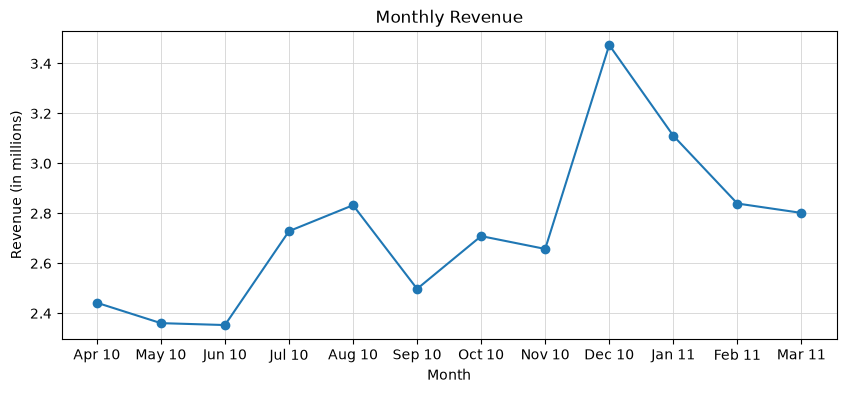

In [75]:
ts.plot_monthly_revenue(daily)

Very interesting, the sales spiked and then declined after winter with a small jump during the summer months, this could coincide with vacations, but let's keep an open mind and explore further.

A **moving average** smooths out the day-to-day noise: 7 days cancels the weekly cycle, 30 days shows the long-term direction.

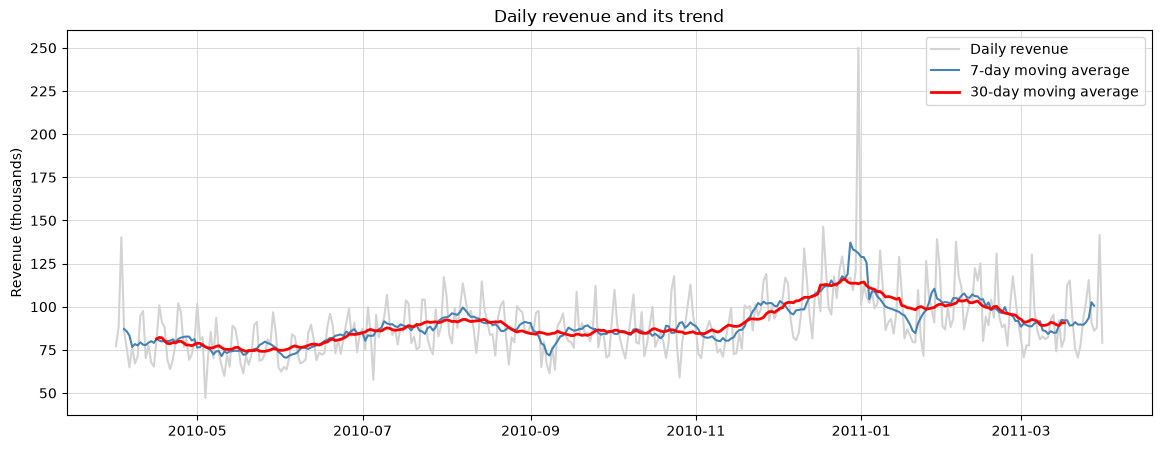

,Value
Lowest 30-day MA,"74,098 (19 May 2010)"
Highest 30-day MA,"116,016 (26 Dec 2010)"
Average day Apr-Jun 2010,"78,629"
Average day Jan-Mar 2011,"97,242"
Growth,+24%


In [76]:
ma = ts.moving_averages(daily)
ts.plot_trend(ma)
ts.trend_summary(daily, ma)

- **The café grew over the year**: an average day in Jan-Mar 2011 brought in ~97k, against ~79k in Apr-Jun 2010 (**+24%**).
- The **low point** was mid-May (~74k per day), the **high point** the last week of December (~116k), driven by the holidays and New Year's Eve.
- After December sales go down again, but stay well above the spring 2010 level.
- Caveat: with only one year we can't tell real growth apart from a yearly cycle. A second year of data would settle this.

<a id="step-5-2"></a>
#### Step 5.2 - Structural decomposition
Daily revenue split into **trend** (7-day moving average), **weekly seasonality** (average effect of each weekday, $S_{t+7} = S_t$) and **noise** (the rest).

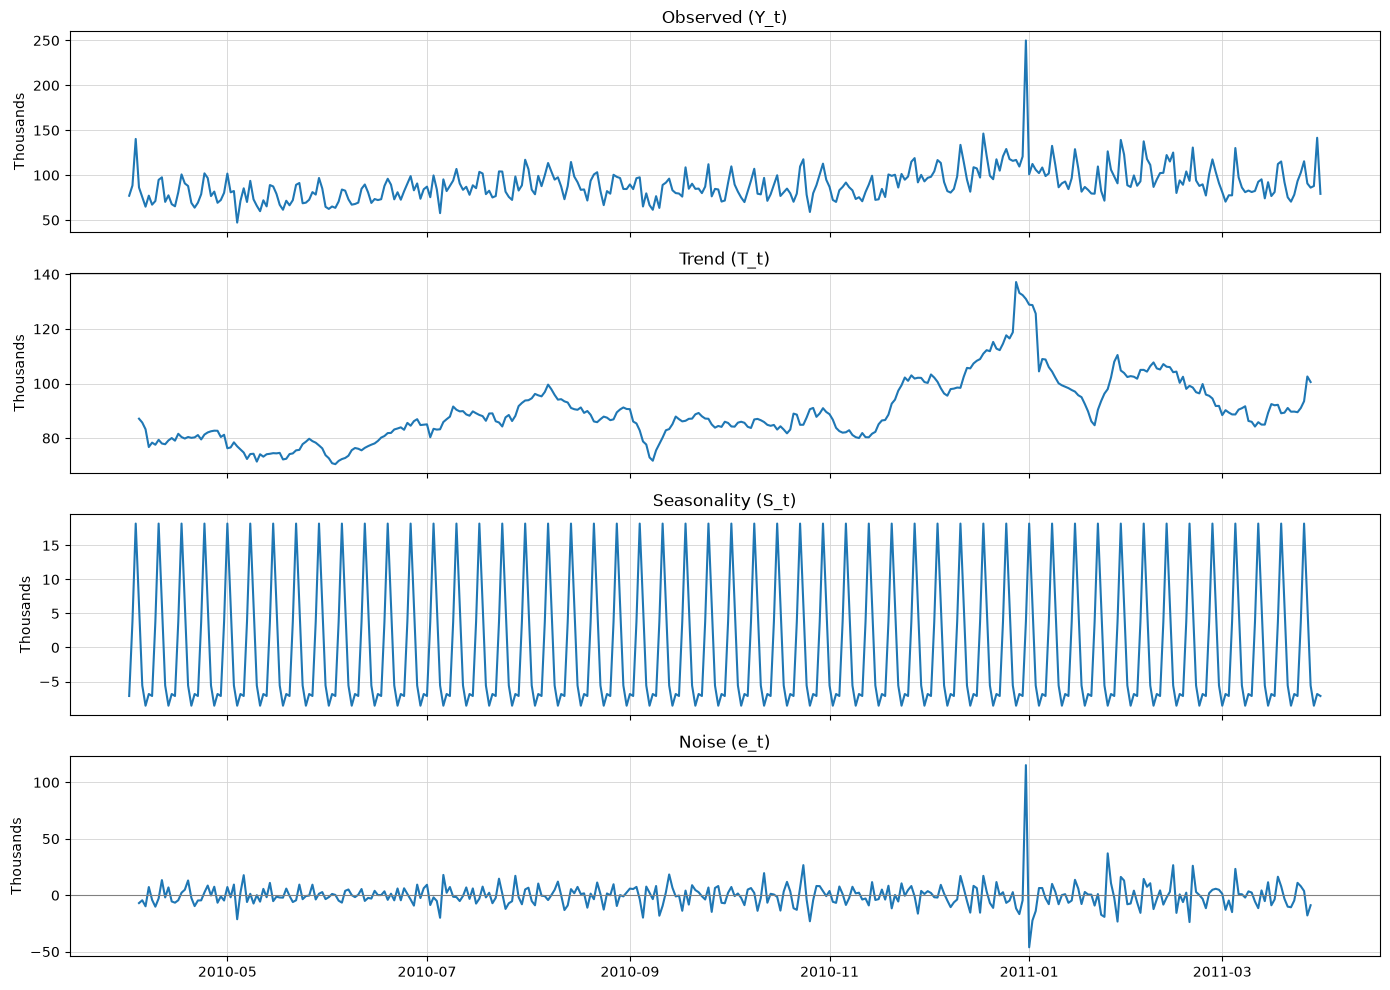

,Share of variance
Trend (T_t),0.39
Seasonality (S_t),0.24
Noise (e_t),0.34


In [77]:
dec = ts.decompose(daily, period=7)
ts.plot_decomposition(dec)
ts.variance_share(dec)

In [78]:
ts.biggest_surprises(dec)

,Revenue,Expected (T_t + S_t),Noise (e_t)
Date,,,
Fri 31 Dec 2010,249995.0,134744.0,115251.0
Sat 01 Jan 2011,100973.0,147071.0,-46097.0
Tue 25 Jan 2011,126498.0,89394.0,37104.0
Sun 24 Oct 2010,117691.0,91015.0,26676.0
Mon 14 Feb 2011,125190.0,98556.0,26634.0
Sun 20 Feb 2011,130753.0,104646.0,26107.0


- Three forces of similar size: the **trend explains ~39%** of the daily variation, the **weekly cycle ~24%** and **~34% is noise**.
- **Weekly pattern**: Saturday is ~18k above the trend, Sunday ~6k and Friday ~4k, while Monday to Thursday are 6-9k below it.
- The **noise roughly doubles in the second half of the year**: busier months are less predictable, so a multiplicative model (or the log of revenue) may fit better than an additive one.
- **The biggest surprises are special days and big bookings** (checked in Step 6):
  - **New Year's Eve** made ~250k, almost 3x a normal day. The dip on 1 January is partly a side effect of that huge value on the moving average.
  - **Tue 25 Jan** was ~37k above expected: that day had a **party booking for 23 people** (14,231, the biggest bill of the year).
  - **Valentine's Day** was ~27k above a normal Monday.
  - **Sun 20 Feb** had one of the five biggest group orders (~8k). Sun 24 Oct has no obvious explanation.

<a id="step-5-3"></a>
#### Step 5.3 - Seasonality and recurring cycles
<a id="step-5-3-1"></a>
##### Step 5.3.1 - Hourly cycle

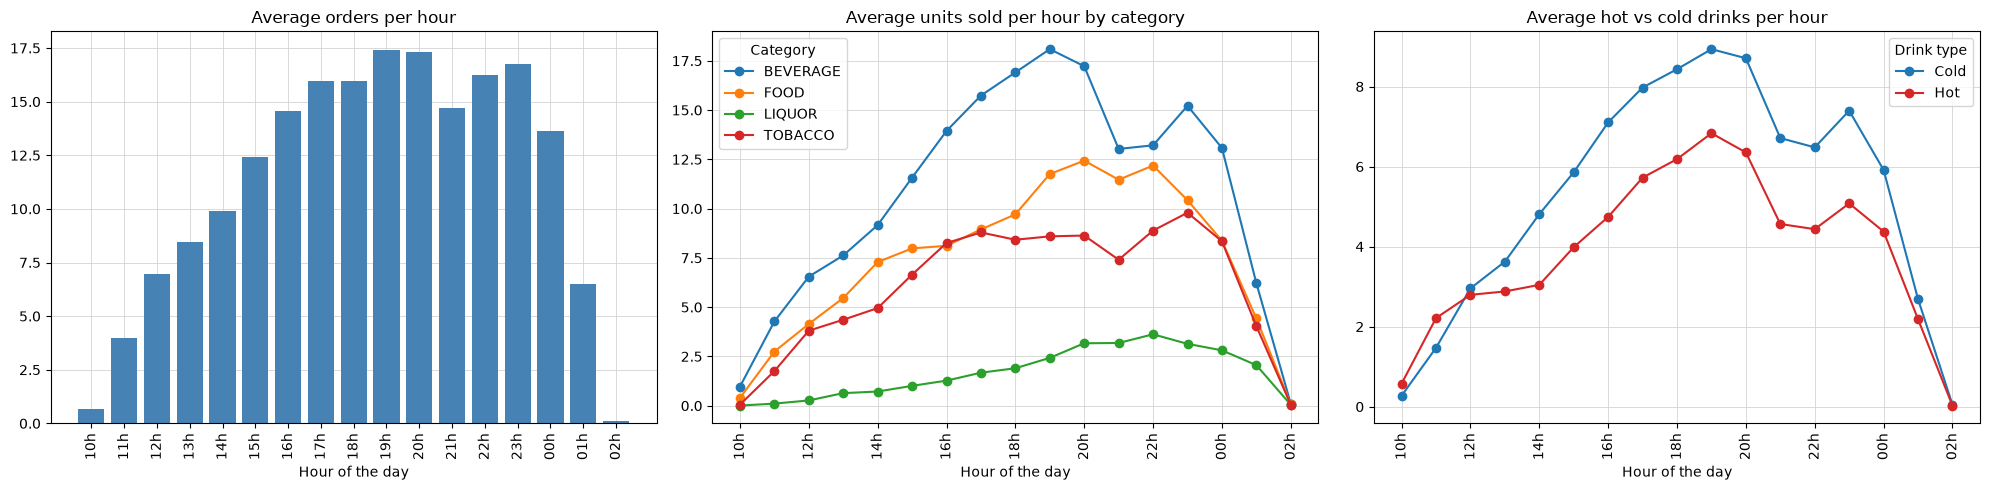

,Value
Busiest hour,19h (17.4 orders per day)
Orders before 15h,16%
Orders from 19h until closing,54%
Orders after midnight,11%


In [79]:
ts.plot_hourly(df_copy, df_orders, beverages, n_days)
ts.hourly_summary(df_orders, n_days)

**There is no morning coffee rush, this is an evening and night business:**
- The café opens around **10h** and takes its last orders around **02h**.
- Only **16%** of orders come before 15h, while **54%** come from 19h until closing. The **busiest hour is 19h**, and it stays busy until midnight, apart from a short dip at 21h after the dinner rush.
- In the late morning most drinks are hot (~70% at 10h), but the volume is tiny. From the early afternoon on, about **60% of the drinks are cold** (shakes, iced teas, lemonades).
- **Liquor** peaks around 22h and **tobacco** (hookah) around 23h: the late evening is the bar/lounge part of the business.

<a id="step-5-3-2"></a>
##### Step 5.3.2 - Weekly cycle

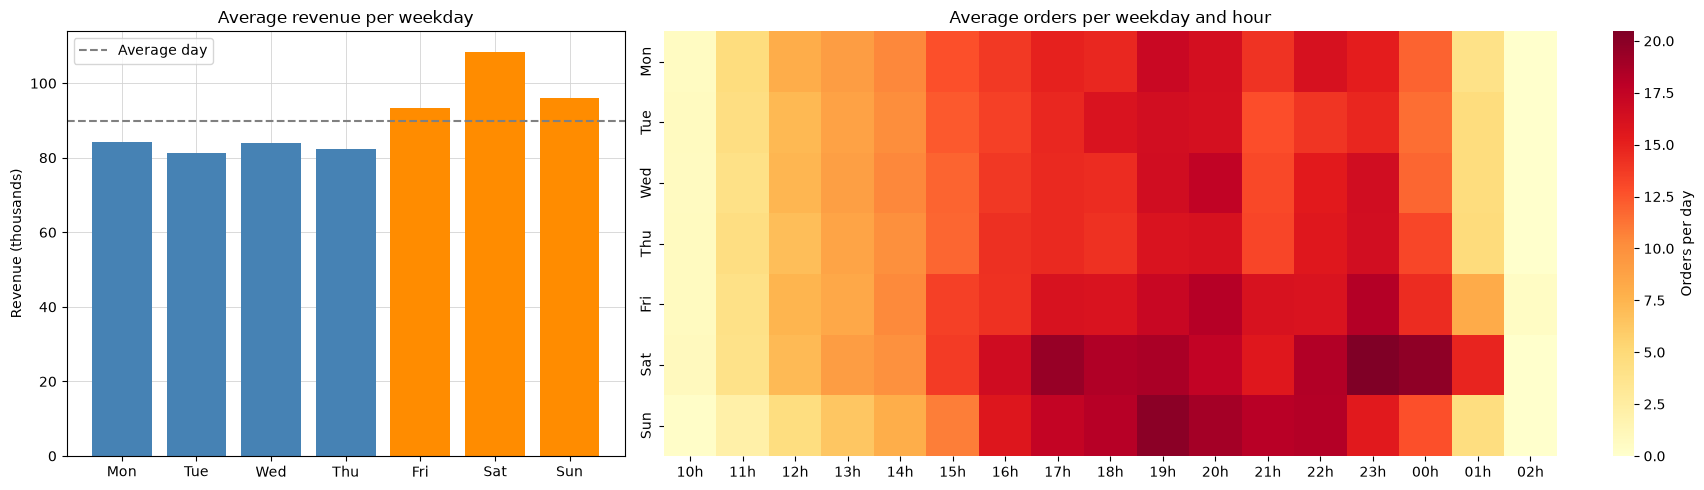

,Avg revenue,Avg orders,Seasonal effect (S_t),Avg order value
Mon,84220.0,184.0,-5585.0,458.0
Tue,81211.0,178.0,-8557.0,455.0
Wed,83868.0,182.0,-6832.0,461.0
Thu,82288.0,181.0,-7129.0,454.0
Fri,93291.0,201.0,3777.0,465.0
Sat,108501.0,224.0,18203.0,483.0
Sun,95921.0,191.0,6122.0,501.0


In [80]:
ts.plot_weekly(daily, df_orders)
ts.weekday_table(daily, df_orders, dec)

The heatmap shows that most of Saturday's extra orders come **between 00h and 02h, which is really Friday night**. So we also look at the **business day**, where orders before 06h count for the previous evening.

In [81]:
business_daily = ts.business_day_revenue(df_orders, daily)
ts.calendar_vs_business_day(daily, business_daily)

,Avg revenue (calendar day),Avg revenue (business day)
Mon,84220.0,84169.0
Tue,81211.0,81551.0
Wed,83868.0,84537.0
Thu,82288.0,85927.0
Fri,93291.0,98904.0
Sat,108501.0,98873.0
Sun,95921.0,95044.0


- **Weekends are the peak**: by calendar date Saturday makes ~109k against ~81k on Tuesday (**+34%**), with more orders (224 vs 178) and slightly bigger orders.
- By **business day**, **Friday and Saturday nights are equally strong (~99k each)**, followed by Sunday (~95k). Monday to Thursday stay around 81-86k.
- Sunday has the **highest average order value (~501)**, which suggests bigger groups or longer visits.
- The real peaks for staffing are **Friday and Saturday evenings, including the hours after midnight**.

<a id="step-5-3-3"></a>
##### Step 5.3.3 - Monthly / seasonal cycle
Beverages are labelled hot or cold from keywords in their names.

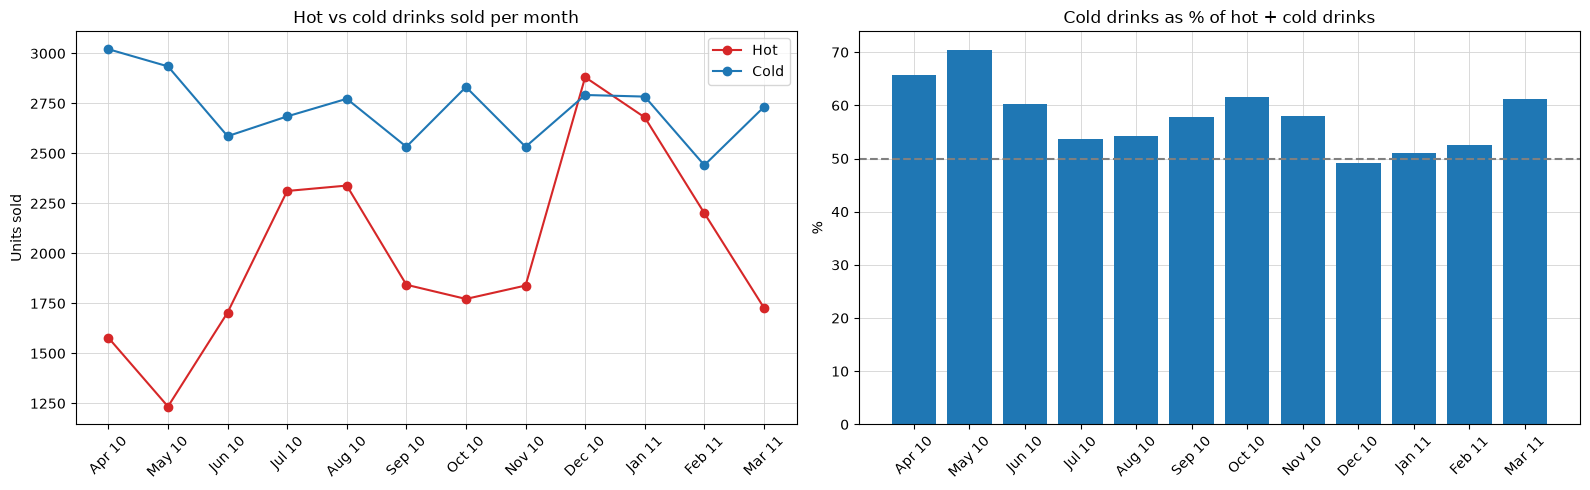

In [82]:
drinks = ts.drinks_per_month(beverages)
ts.plot_drinks_per_month(drinks)

**Hot drinks drive the seasonality, not cold ones:**
- **Cold drinks are stable** all year (~2,400-3,000 per month, including the shakes): no real "summer surge".
- **Hot drinks more than double**, from ~1,230 in May to ~2,880 in December, and stay high in Dec-Jan.
- Cold drinks are the majority in every month, but their share is highest in **April-May (66-70%)** and lowest in **December-January (49-51%)**. Hot drinks also rise in July-August, which fits the cooler monsoon season if the café is in India.
- The slow months (Apr-Jun) are the ones where hot drinks sell least, so promoting cold drinks then could help fill the gap.

<a id="step-5-4"></a>
#### Step 5.4 - Detrending and stationarity
A **stationary** series keeps the same mean and spread over time, which most forecasting models need. We remove the trend by **differencing**: the change vs the day before ($Y'_t = Y_t - Y_{t-1}$) and vs the same weekday last week ($Y_t - Y_{t-7}$). We also try the weekly difference of **log revenue**, and check every series with the **Augmented Dickey-Fuller (ADF) test** (H0: the series is not stationary, so a p-value below 0.05 means stationary).

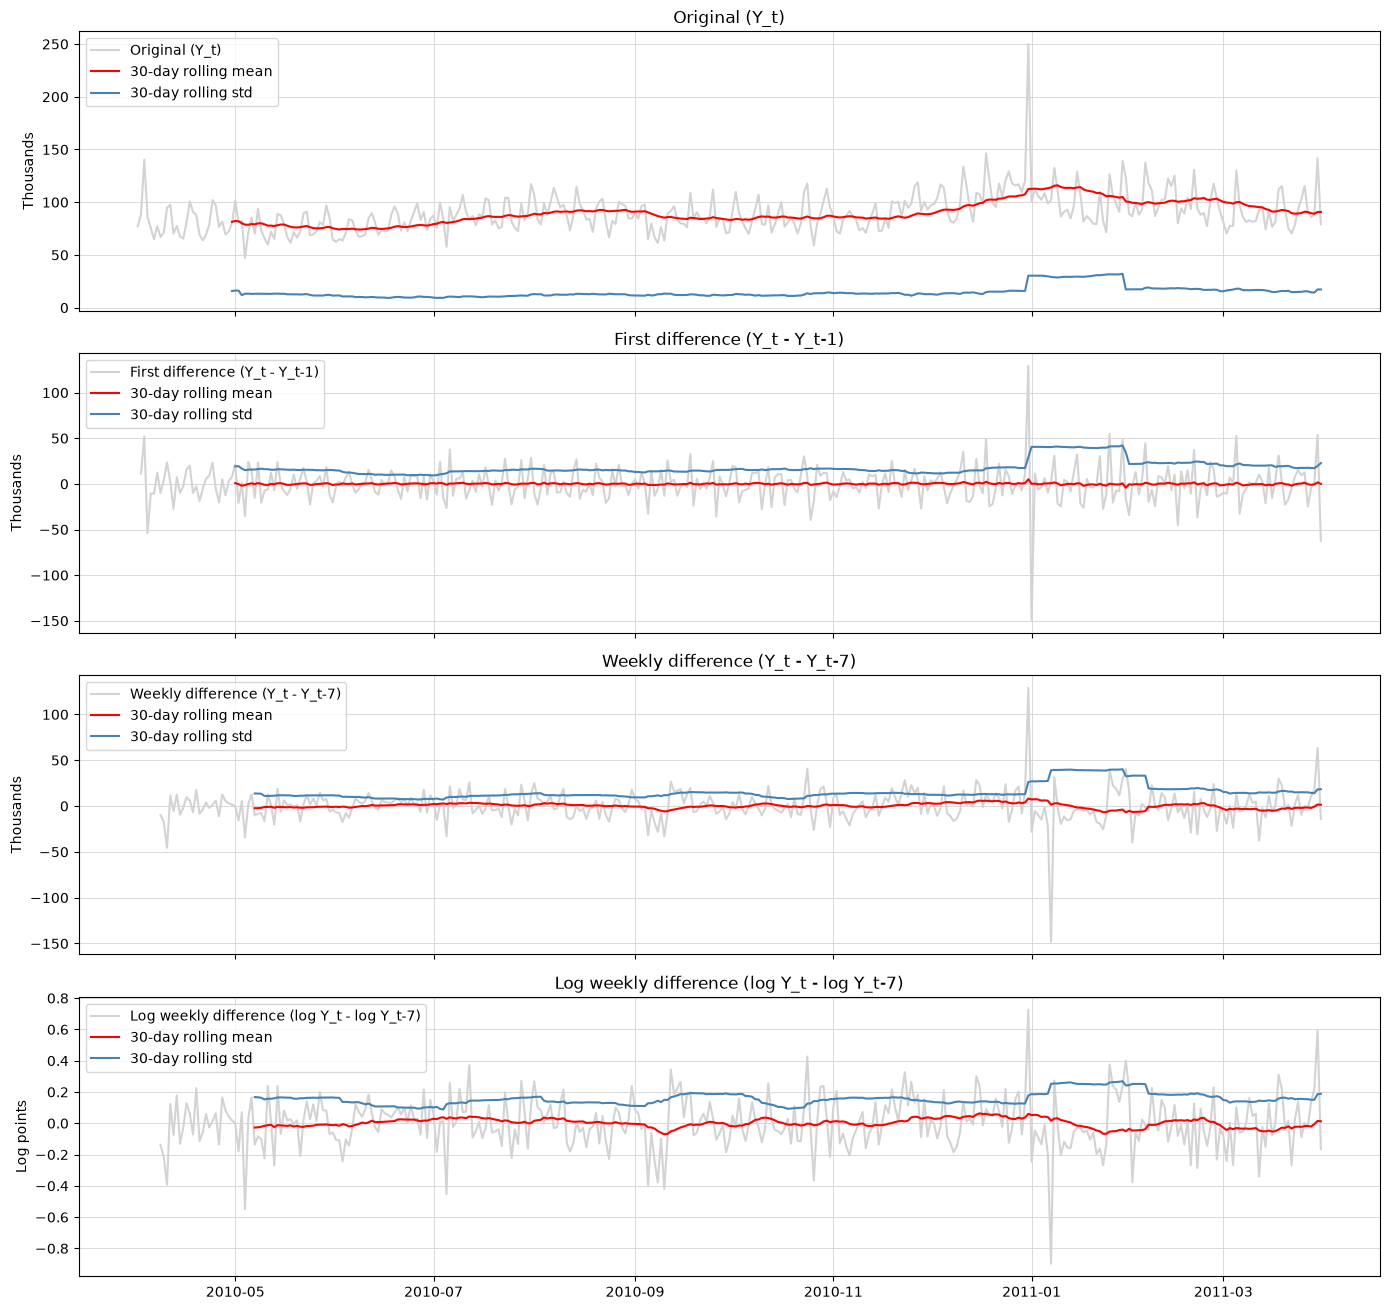

c:\Users\Telmo Claro\Documents\GitHub\ds_project_a\time_series.py:302: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  "ADF p-value": adfuller(s, autolag="AIC")[1]})
c:\Users\Telmo Claro\Documents\GitHub\ds_project_a\time_series.py:302: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  "ADF p-value": adfuller(s, autolag="AIC")[1]})
c:\Users\Telmo Claro\Documents\GitHub\ds_proje

,Original (Y_t),First difference (Y_t - Y_t-1),Weekly difference (Y_t - Y_t-7),Log weekly difference (log Y_t - log Y_t-7)
Mean 1st half,83199.75,-29.20,-43.98,0.00
Mean 2nd half,96522.08,40.72,569.03,0.01
Std 1st half,13405.08,14927.07,11796.08,0.15
Std 2nd half,20520.31,23524.06,21316.60,0.18
Std ratio (2nd / 1st half),1.53,1.58,1.81,1.23
Autocorrelation lag 1,0.44,-0.31,0.06,0.11
Autocorrelation lag 7,0.57,0.26,-0.35,-0.35
ADF p-value,0.11,0.00,0.00,0.00


In [83]:
diffs = ts.differenced_series(daily)
ts.plot_differencing(diffs)
ts.stationarity_table(diffs)

- The **original series is not stationary**: the average day rises from ~83k to ~97k between the two halves of the year, the spread grows too, and the ADF test can't reject non-stationarity (p = 0.11).
- **Differencing removes the trend**: all differenced series have a mean close to 0 and pass the ADF test (p < 0.01).
- Only the **weekly differences also remove the weekly cycle** (the first difference still has a lag-7 autocorrelation of 0.26).
- The **spread still grows** with plain differencing (the std of the weekly difference is 1.8x higher in the second half). Taking the **log first** reduces this to 1.2x, so for modelling we recommend **log revenue + weekly differencing**.

<a id="step-5-5"></a>
#### Step 5.5 - Key takeaways
1. **The business is growing**: +24% per day from Apr-Jun 2010 to Jan-Mar 2011, with a peak in December.
2. **It's an evening/night café**: more than half of the orders come after 19h and there is no morning rush. The quiet late morning and lunch hours are the biggest room for growth.
3. **Friday and Saturday nights are the strongest**, about +19% above Monday-Wednesday, with many sales after midnight.
4. **Hot drinks drive the seasons**: they more than double from May to December while cold drinks stay flat.
5. **Special days matter**: New Year's Eve was almost 3x a normal day, and party bookings, group orders and Valentine's Day also stand out.
6. **For forecasting**: use log revenue with weekly differencing (stationary by the ADF test) and add calendar features (weekday, special days, business day) in Step 7.

<a id="step-6"></a>
### Step 6 - Category Performance and Relationship Discovery
Now we look at **what** the café sells: how each category performs, how concentrated sales are, how the mix changes through the day, which products sell best per month and season, how variables relate to each other, which anomalies we found, and we confirm the main patterns with statistical tests.

In [84]:
df_copy = cat.add_daypart(df_copy)
df_orders = cat.add_daypart(df_orders)

<a id="step-6-1"></a>
#### Step 6.1 - Category performance
For every category: how many units it sells, how much revenue it brings in, the average revenue per unit, how many products it has and in how many orders it appears.

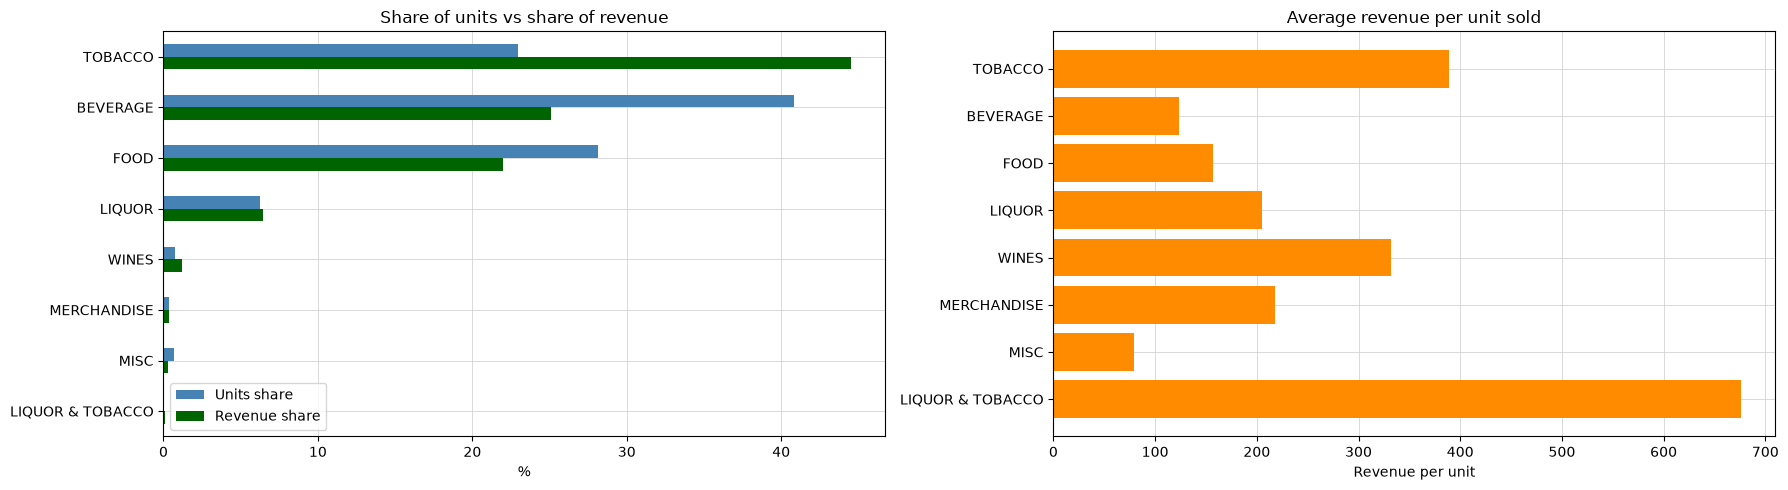

,Units,Revenue,Products,Units share,Revenue share,Revenue per unit,Revenue per product,% of orders
Category,,,,,,,,
TOBACCO,37544,"14,595,949",57,23.0%,44.5%,389,"256,069",48.4%
BEVERAGE,66812,"8,240,586",131,40.9%,25.1%,123,"62,905",53.4%
FOOD,45999,"7,216,376",194,28.1%,22.0%,157,"37,198",37.8%
LIQUOR,10261,"2,106,568",33,6.3%,6.4%,205,"63,835",8.0%
WINES,1195,"396,791",58,0.7%,1.2%,332,"6,841",1.2%
MERCHANDISE,551,"120,074",87,0.3%,0.4%,218,"1,380",0.5%
MISC,1094,"86,990",13,0.7%,0.3%,80,"6,692",1.3%
LIQUOR & TOBACCO,63,"42,562",4,0.0%,0.1%,676,"10,640",0.1%


In [85]:
performance = cat.category_performance(df_copy, df_orders)
cat.plot_category_performance(performance)
cat.show_category_performance(performance)

- **Tobacco (hookah) is the money maker**: only 23% of the units but **45% of the revenue**, because a hookah costs ~390 per unit, 3x a drink. It's in almost half of all orders (48%).
- **Beverage sells the most units (41%)** but brings in 25% of the revenue: drinks are cheap (~123 per unit), they bring people in rather than money.
- **Food** has the **most products (194)** but earns the least per product (~37k per product vs ~256k for tobacco): a long menu with many small sellers.
- **Liquor and wine are small** (7.6% of revenue together) and appear in only ~9% of the orders, partly because alcohol is billed separately (see 6.6). **Wines** have 58 products for 1.2% of revenue.

<a id="step-6-2"></a>
#### Step 6.2 - Concentration of sales (Pareto)
The 80/20 rule says a small part of the products often makes most of the revenue. With 577 products on the menu, how concentrated is the café's revenue?

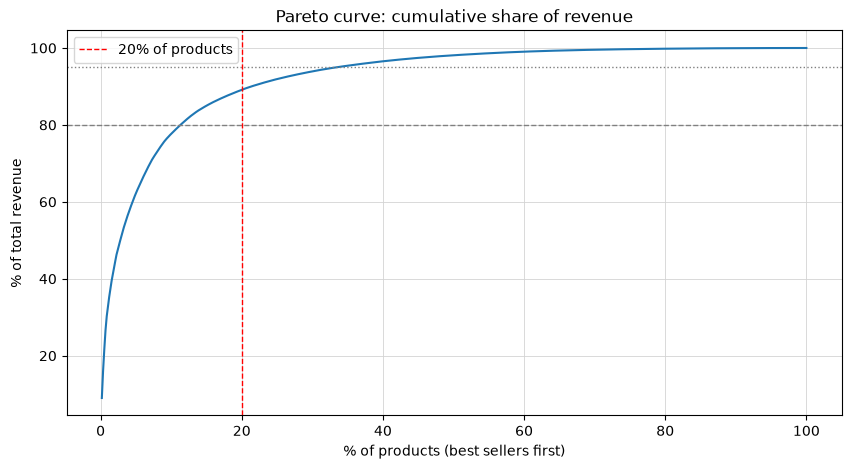

,Value
Products making 50% of revenue,17 (3% of products)
Products making 80% of revenue,66 (11% of products)
Products making 95% of revenue,194 (34% of products)
Products sold less than once a month (< 12 units),191 (33% of products)
Revenue of those rare products,0.9%


In [86]:
cat.plot_pareto(df_copy)
cat.pareto_summary(df_copy)

- Revenue is **very concentrated**: **17 products (3%) make half of the revenue** and **66 products (11%) make 80%**, even stronger than the 80/20 rule.
- On the other side, **191 products (a third of the menu) sell less than once a month**, and together they bring in **less than 1% of the revenue**.
- Business implication: the menu could be **shortened a lot** without losing sales, which saves stock, waste and kitchen complexity. Before removing items we would check if they are bought together with best sellers (Part 2).

<a id="step-6-3"></a>
#### Step 6.3 - Category mix through the day and the week
Step 5 showed *when* the café is busy. Here we look at *what* it sells at those moments. We split the day into parts based on the opening hours.

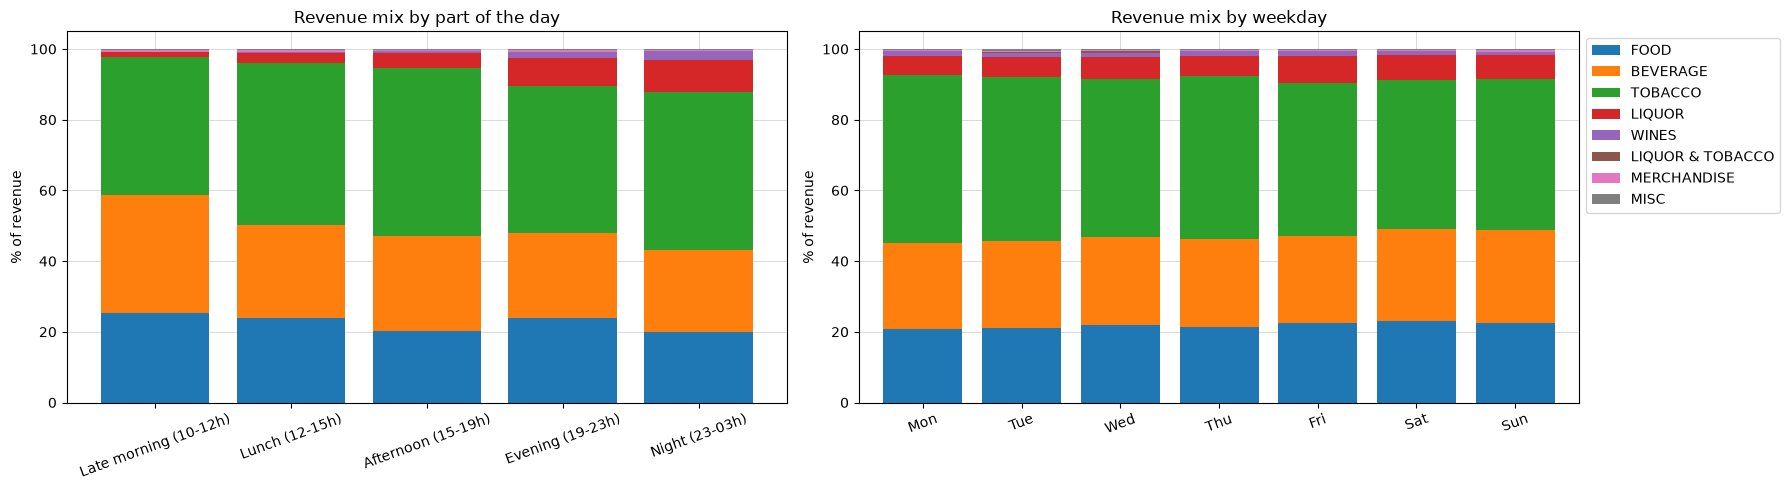

,Orders,Revenue,Avg_order_value,Share of revenue,Top category
Daypart,,,,,
Late morning (10-12h),1702,"613,387",360.0,2%,TOBACCO (39%)
Lunch (12-15h),9248,"3,858,510",417.0,12%,TOBACCO (46%)
Afternoon (15-19h),21502,"9,716,733",452.0,30%,TOBACCO (47%)
Evening (19-23h),23971,"11,562,562",482.0,35%,TOBACCO (42%)
Night (23-03h),13559,"7,054,702",520.0,22%,TOBACCO (45%)


In [87]:
cat.plot_category_mix(df_copy)
cat.daypart_table(df_copy, df_orders)

- **Hookah is the biggest earner in every part of the day** (39-47% of revenue), even at lunch. It's not only a night product.
- **Drinks matter most in the late morning** (33% of revenue), **alcohol grows through the day**: liquor goes from 1% in the late morning to 9% at night, wine from 0.1% to 2.3%.
- The **evening (19-23h) brings in the most revenue (35%)**, followed by the afternoon (30%) and the night (22%). The late morning is only 2%.
- **Orders get bigger as the day goes on**: the average order is ~360 in the late morning and ~520 at night.
- The **mix is almost the same every weekday**. From Friday to Sunday people order a bit more food and liquor (and drinks on Sat-Sun), so tobacco's share drops from ~45-48% to ~42-43%.

TODO:

Add the same but per category (choose 1 or 2).

<a id="step-6-4"></a>
#### Step 6.4 - Most sold products per month and season
This answers two of our Step 1 questions. Seasons are the four quarters of the data year.

<a id="step-6-4-1"></a>
##### Step 6.4.1 - Top products per month

In [88]:
cat.top_products_per_period(df_copy, df_copy["Date"].dt.to_period("M"))

Rank,1,2,3
Period,,,
2010-04,GREAT LAKES SHAKE (560),MINT FLAVOUR SINGLE (553),NIRVANA HOOKAH SINGLE (547)
2010-05,NIRVANA HOOKAH SINGLE (639),GREAT LAKES SHAKE (580),MINT FLAVOUR SINGLE (514)
2010-06,NIRVANA HOOKAH SINGLE (723),CAPPUCCINO (588),GREAT LAKES SHAKE (503)
2010-07,NIRVANA HOOKAH SINGLE (754),CAPPUCCINO (703),GREAT LAKES SHAKE (536)
2010-08,NIRVANA HOOKAH SINGLE (831),CAPPUCCINO (685),MINT FLAVOUR SINGLE (494)
2010-09,NIRVANA HOOKAH SINGLE (828),CAPPUCCINO (605),MINT FLAVOUR SINGLE (445)
2010-10,NIRVANA HOOKAH SINGLE (769),CAPPUCCINO (580),SAMBUCA (570)
2010-11,NIRVANA HOOKAH SINGLE (673),GREAT LAKES SHAKE (496),CAPPUCCINO (495)
2010-12,NIRVANA HOOKAH SINGLE (790),CAPPUCCINO (778),GREAT LAKES SHAKE (535)


<a id="step-6-4-2"></a>
##### Step 6.4.2 - Top products per season

In [89]:
cat.top_products_per_period(df_copy, cat.season_of(df_copy["Date"]), n=5)

Rank,1,2,3,4,5
Period,,,,,
Apr-Jun 2010,NIRVANA HOOKAH SINGLE (1909),GREAT LAKES SHAKE (1643),MINT FLAVOUR SINGLE (1559),CAPPUCCINO (1543),SAMBUCA (1124)
Jul-Sep 2010,NIRVANA HOOKAH SINGLE (2413),CAPPUCCINO (1993),GREAT LAKES SHAKE (1447),MINT FLAVOUR SINGLE (1416),SAMBUCA (1281)
Oct-Dec 2010,NIRVANA HOOKAH SINGLE (2232),CAPPUCCINO (1853),SAMBUCA (1561),GREAT LAKES SHAKE (1548),MINT FLAVOUR SINGLE (1340)
Jan-Mar 2011,NIRVANA HOOKAH SINGLE (2132),CAPPUCCINO (1755),MINT FLAVOUR SINGLE (1704),GREAT LAKES SHAKE (1276),POUTINE WITH FRIES (994)


<a id="step-6-4-3"></a>
##### Step 6.4.3 - Products gaining or losing share between seasons
The top products barely change, so we also look at which products **gain or lose share** between the warm quarter (Apr-Jun) and the cooler half of the year (Oct-Mar), for products sold in every season:

In [90]:
cat.season_changes(df_copy)

,Share Apr-Jun (%),Share Oct-Mar (%),Change (pp)
Item Desc,,,
TUBORG,1.49,2.05,0.55
MASALA CHAI CUTTING,1.51,1.86,0.35
MISCHIEF HOOKAH SINGLE,0.26,0.60,0.35
KF DRAUGHT PITCHER (2LTR),0.19,0.50,0.31
POUTINE WITH FRIES,2.10,2.38,0.29
RED BULL 2+1,0.51,0.79,0.29
GREEN APPLE FLAVOUR SINGLE,1.46,1.74,0.28
QUA MINERAL WATER(1000ML),2.14,2.41,0.27
GREAT LAKES SHAKE,4.47,3.31,-1.15


- The **top products are the same all year**: **Nirvana Hookah Single** is number 1 in 10 of the 12 months (the Great Lakes Shake leads in April 2010, Cappuccino in January 2011), followed by Cappuccino, Great Lakes Shake and Mint Flavour.
- The **Great Lakes Shake** is in the top 3 in most months, but it is the product that **loses the most share** in Oct-Mar compared to Apr-Jun, together with other cold products (Jr. Chill Avalanche, Berry Blast, Miami Melons, Country Lemonade).
- **Winter winners** are hot and "heavier" products: **masala chai**, poutine, and beer (**Tuborg**, KF pitcher).
- **KF Draught 1 litre loses share while the KF pitcher gains**: a possible effect of a price or menu change, a good candidate for Part 3.

<a id="step-6-5"></a>
#### Step 6.5 - Relationships
- **Price vs units sold**: do cheaper products sell more? We use the **Spearman** correlation because prices and units are very skewed (it compares ranks instead of values).
- **Categories over time**: do the categories rise and fall together from day to day?

<a id="step-6-5-1"></a>
##### Step 6.5.1 - Price vs units sold

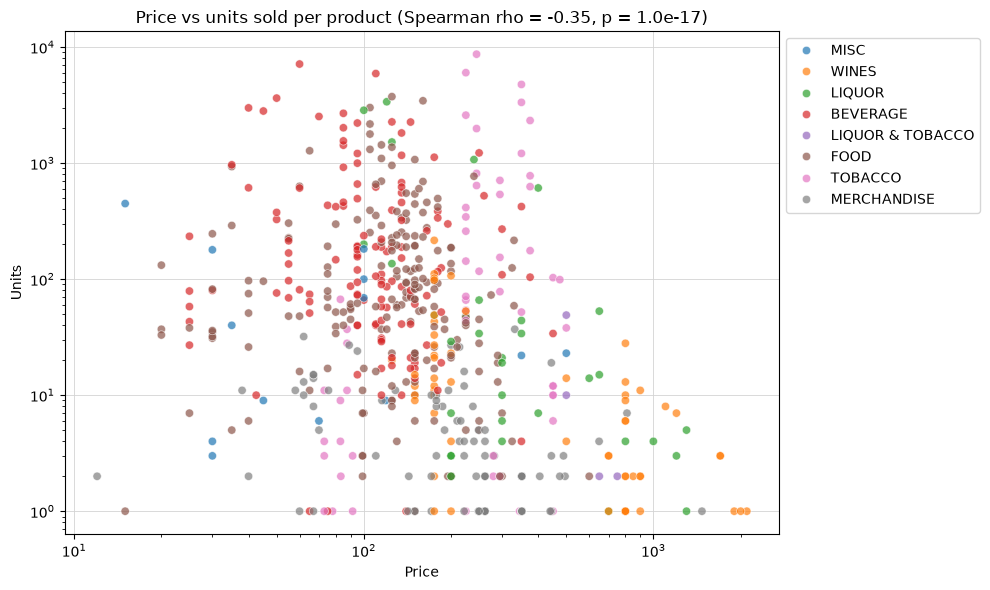

,Products,Spearman rho,p-value
All products,576,-0.35,0.000
FOOD,193,-0.09,0.213
BEVERAGE,131,-0.18,0.038
TOBACCO,57,0.3,0.026
LIQUOR,33,-0.53,0.001
WINES,58,-0.58,0.000


In [91]:
products = cat.price_vs_units(df_copy)
cat.plot_price_vs_units(products)
cat.price_units_correlation(products)

<a id="step-6-5-2"></a>
##### Step 6.5.2 - Categories over time

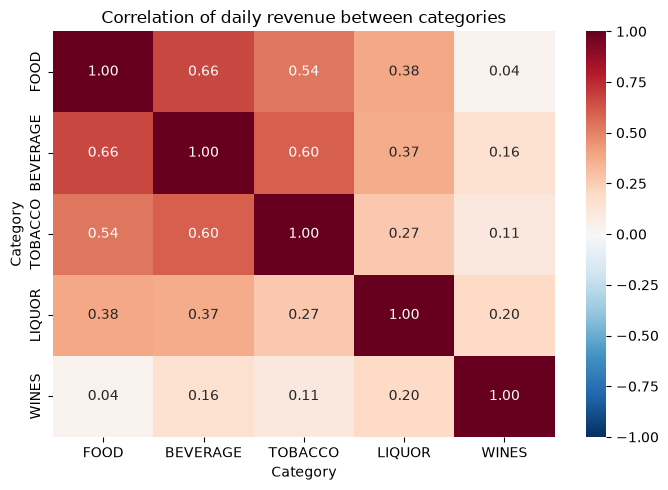

In [92]:
cat.plot_daily_category_correlation(df_copy)

- **Overall, cheaper products sell more** (Spearman rho = -0.35), but that's mostly because categories have different price levels.
- **Within categories** the picture is different: for **liquor and wine** cheaper clearly sells more (rho -0.53 and -0.58), for **food** price doesn't matter (no significant relation), and for **tobacco the more expensive hookahs sell more** (rho +0.30): customers are willing to pay for premium hookahs.
- **Food, beverage and tobacco rise and fall together** from day to day (correlations 0.54-0.66): they are driven by the same thing, the number of visitors. **Liquor** follows less (0.27-0.38) and **wine** is almost independent (rare, irregular sales).

<a id="step-6-6"></a>
#### Step 6.6 - Anomalies
Things in the data that don't behave like normal sales, found during the previous steps.

<a id="step-6-6-1"></a>
##### Step 6.6.1 - Items sold for 0.01
Flagged in Step 3:

In [93]:
cat.free_items(df_copy)

,Date,Time,Bill Number,Item Desc,Quantity,Rate,Total
88182,2010-05-09,18:51:51,G0476259,MOTHERS DAY SPL,1,0.01,0.01
88183,2010-05-09,22:21:55,G0476303,MOTHERS DAY SPL,1,0.01,0.01
88184,2010-05-09,22:42:38,G0476311,MOTHERS DAY SPL,1,0.01,0.01
88185,2010-05-09,12:10:55,G0476201,MOTHERS DAY SPL,1,0.01,0.01
88186,2010-05-09,00:39:33,G0476338,MOTHERS DAY SPL,1,0.01,0.01


<a id="step-6-6-2"></a>
##### Step 6.6.2 - The biggest orders
Flagged as outliers in Step 4:

In [94]:
cat.biggest_orders(df_copy, df_orders)

,Date,Time,Unique_Items,Quantity,Total,Most expensive line
Bill Number,,,,,,
G0522713,2011-01-25,21:21:02,1,23,14231.25,PARTY CHARGES @ 500/-
G0481424,2010-06-11,21:51:46,15,64,11415.95,ASSORTED TAPAS (2)NONVEG
G0518491,2011-01-02,23:27:37,15,58,8985.96,CHEESE FONDUE
G0516596,2010-12-25,14:47:32,12,52,8602.71,LEMON ICED TEA
G0527570,2011-02-20,21:24:40,16,41,8111.84,LEMON ICED TEA


<a id="step-6-6-3"></a>
##### Step 6.6.3 - Two bill series
Bill numbers start with `G` or `N`. We compared both:

In [95]:
cat.bill_series(df_copy, df_orders)

,Orders,Avg_order_value,Avg_products,Share of orders,Alcohol share of revenue
Bill series,,,,,
G,63775,474.96,2.16,91%,0%
N,6207,405.22,1.14,9%,100%


<a id="step-6-6-4"></a>
##### Step 6.6.4 - Menu changes
While fixing the item names (Step 3) we saw names that stop being used in December and new names from January. We count, per month, how many products are sold for the first and the last time:

In [96]:
print("Days with the most new products in January 2011:")
print(cat.first_sale_dates(df_copy).to_string())
cat.menu_changes(df_copy)

Days with the most new products in January 2011:
Date
2011-01-07    18
2011-01-08    19
2011-01-09     9
2011-01-10     6
2011-01-11     5


,Products sold,New products,Products sold for the last time
Date,,,
Apr 10,303,0,20
May 10,293,36,11
Jun 10,315,39,18
Jul 10,315,26,18
Aug 10,305,14,14
Sep 10,298,12,22
Oct 10,281,8,9
Nov 10,281,6,5
Dec 10,318,22,50


<a id="step-6-6-5"></a>
##### Step 6.6.5 - Summary of the anomalies
| Anomaly | What we found | What we do with it |
|---|---|---|
| **Items at 0.01** | 5 lines of `MOTHERS DAY SPL` on 9 May 2010: a free gift added to bills | Keep: real event, no effect on revenue |
| **Biggest bill (14,231)** | `PARTY CHARGES @ 500/-` x 23 on 25 Jan 2011: a party booking. This explains the 25 Jan surprise in Step 5 | Keep, flag as special day (Step 7) |
| **Very large orders** (40-64 items) | Group orders on 11 Jun, Christmas Day, 2 Jan and 20 Feb | Keep: real sales, part of the order outliers in Step 4 |
| **Two bill series** | `N` bills (9% of orders) contain **only alcohol**, `G` bills **never** contain alcohol: the café bills alcohol separately | Important for Part 2: a beer and a hookah in the same visit end up on **two different bills** |
| **New menu in January 2011** | 37 new products on 7-8 January, 73 new products in January, while 125 products are sold for the last time in Dec-Jan | Flag old/new menu (Step 7), candidate for Part 3 |
| **December MISC spike** | New December products (sheeshas, KF draft mug, spirits) were booked as MISC | Fixed in Step 3 |
| **New Year's Eve** | ~250k, almost 3x a normal day (Step 5) | Flag as special day (Step 7) |

<a id="step-6-7"></a>
#### Step 6.7 - Statistical tests
So far we described patterns, now we check that they are not just chance. Daily revenue and order values are skewed (Step 4), so we use **non-parametric tests**, which don't assume normal data:
- **Mann-Whitney U**: are Fri/Sat nights really stronger than the other nights? (business days, Step 5)
- **Kruskal-Wallis**: does revenue differ between weekdays? Does the order value differ between parts of the day?
- **Chi-square test of independence**: does the choice between hot and cold drinks depend on the season?

We use a significance level of 5%. With this much data almost any difference becomes significant, so we also report an **effect size**: how big the difference really is.

In [97]:
business_daily = ts.business_day_revenue(df_orders, daily)
chi_test, drinks_per_season = cat.test_drink_type_vs_season(beverages)
cat.test_summary(
    cat.test_weekend_vs_weekday(business_daily),
    cat.test_weekdays(business_daily),
    chi_test,
    cat.test_order_value_by_daypart(df_orders),
)

,Chi2,Degrees of freedom,Effect size (Cramer's V),Effect size (rank-biserial r),H statistic,Highest median,Lowest median,Median Fri/Sat,Median Sun-Thu,p-value
Mann-Whitney U (one-sided): Fri/Sat business days make the same revenue as Sun-Thu,,,,0.50,,,,"96,794","84,617",6.7e-14
Kruskal-Wallis H: All weekdays have the same revenue distribution,,,,,80.9,,,,,2.3e-15
Chi-square test of independence: Hot/cold choice is the same in every season,436,3,0.09,,,,,,,3.4e-94
Kruskal-Wallis H: Order value is the same in every part of the day,,,,,856.4,Night (23-03h) (446),Late morning (10-12h) (323),,,4.6e-184


In [98]:
drinks_per_season

Drink type,Cold,Hot
Season,,
Apr-Jun 2010,8542,4516
Jul-Sep 2010,7991,6494
Oct-Dec 2010,8157,6492
Jan-Mar 2011,7957,6609


All four tests are significant (p < 0.001), but the effect sizes tell us which differences really matter:
- **Fri/Sat nights are stronger than the other nights**: median ~97k vs ~85k per business day, with a **large effect** (rank-biserial r = 0.50). Weekdays also differ overall (Kruskal-Wallis). This confirms the weekly cycle from Step 5.
- **The hot/cold choice depends on the season**, but the effect is **small** (Cramer's V = 0.09): cold drinks are the majority in every season, winter only shifts the balance a bit towards hot drinks.
- **Order value differs between parts of the day**: the median order goes from ~323 in the late morning to ~446 at night.
- Limitation: each day and order is treated as independent, while days next to each other are related (Step 5). With this much data the p-values are tiny anyway, so the effect sizes are the more useful numbers.

<a id="step-6-8"></a>
#### Step 6.8 - Key takeaways
1. **Hookah is the core business**: 45% of revenue from 23% of the units, the biggest earner in every part of the day, and premium hookahs sell better than cheap ones.
2. **Drinks bring people in, hookah brings in the money**: beverages are 41% of units but only 25% of revenue.
3. **The menu is too long**: 66 products make 80% of the revenue, a third of the menu sells less than once a month.
4. **Alcohol is billed separately**, so baskets with alcohol and hookah/food are split over two bills. We must keep this in mind in Part 2.
5. **A new menu started on 7 January 2011**, and several big events (party booking, group orders, New Year's Eve) explain the biggest revenue surprises.

<a id="step-7"></a>
### Step 7 - Offensive Data Preparation & Feature Engineering
We turn what we learned in Steps 3-6 into new columns, so the next parts (market basket analysis and our own question) can use them directly. Every feature comes from a finding:

In [99]:
fe.FEATURES

,Level,What it is,Why we need it
Feature,,,
Hour,line + order,Hour of the order (0-23),Hourly cycle (Step 5)
Daypart,line + order,Late morning / Lunch / Afternoon / Evening / N...,Category mix changes through the day (Step 6)
Business day,line + order,"Date, but orders before 06h count for the prev...",A night out doesn't stop at midnight (Step 5)
Weekday,line + order,Weekday of the business day,Weekly cycle (Step 5)
Weekend,line + order,"True for Fri, Sat and Sun nights","Strongest nights (Step 5, test in Step 6)"
Special day,line + order,"Name of the holiday/event, or 'No'",Largest surprises in the decomposition (Step 5)
Menu,line + order,Old menu / New menu (from 7 Jan 2011),Menu change found in Step 6
Bill series,line + order,Main bill (G) / Alcohol bill (N),Alcohol is billed separately (Step 6)
Promo,line,Buy 1 get 1 / Multi-buy / Multi-pack / Combo /...,"Deals are only in the name, not in Discount (S..."


<a id="step-7-1"></a>
#### Step 7.1 - Promotion and base product
When we searched for duplicate item names in Step 3, many names looked almost identical but had a prefix or suffix like `1+1`, `B1G1` or `2+1`, e.g. `VLN CAB SAUV (GLS)` vs `1+1 VLN CAB SAUV (GLS)`, or `CARLSBERG` vs `CARLSBERG 2+1`. These are the **same base product sold as a deal**, at a different price.

We don't merge them with the normal product, because that would mix different prices and quantities. But we don't want to lose that information either: the dataset has a `Discount` column, and **promotions are not recorded there**. They only show up in the product name. So we add two columns:
- `Promo`: the type of deal, found from patterns in the name
- `Base product`: the name without the deal (`1+1 VLN CAB SAUV (GLS)` -> `VLN CAB SAUV (GLS)`), so a product can be compared with and without its deal

| Promo | Pattern in the name | Examples |
|---|---|---|
| **Buy 1 get 1** | starts with `1+1` or `B1G1` | `1+1 KF 1/2 LITER`, `B1G1 ZINZI RED (GLS)` |
| **Multi-buy** | `2+1`, `3+2`, ... | `CARLSBERG 2+1`, `RED BULL 3+2` |
| **Multi-pack** | starts with 2-9 followed by the product | `3 RED BULL`, `2 AXE TWIST` |
| **Combo** | two products joined by ` + ` | `WAFFLES + BEVERAGE`, `2 DOM BEER + 1SPL SHEESHA` |

Names that start with a number but are not a deal are left out on purpose: `4 SEASONS ...` and `2 OCEAN PINOTAGE` are wine brands, `3COURSE ... MEAL` is a set menu and `1 AXE TWIST` is a single item.

In [100]:
df_copy = fe.add_line_features(df_copy)
fe.promo_summary(df_copy)

,Products,Units,Revenue,Lines_with_discount,Revenue share
Promo,,,,,
No promo,535,161323,"32,062,776",262,97.7%
Multi-buy,8,1378,"455,657",3,1.4%
Buy 1 get 1,22,363,"89,936",1,0.3%
Multi-pack,4,327,"123,379",2,0.4%
Combo,8,128,"74,148",0,0.2%


In [101]:
# Which products are on promotion, and what is their base product?
fe.promo_products(df_copy)

Base_product  Units
Promo       Item Desc                                                       
Buy 1 get 1 1+1 BTL4 SEASON WHITE                   BTL4 SEASON WHITE      2
            1+1 GLS 4SEASON RED                       GLS 4SEASON RED     11
            1+1 GLS 4SEASONS WHITE                 GLS 4SEASONS WHITE     13
            1+1 KF 1 LITER                          KF DRAUGHT (1LTR)     48
            1+1 KF 1/2 LITER                      KF DRAUGHT (1/2LTR)    136
            1+1 KF 2 LITER                  KF DRAUGHT PITCHER (2LTR)      7
            1+1 VLN CAB SAUV (BTL)                 VLN CAB SAUV (BTL)      1
            1+1 VLN CAB SAUV (GLS)                 VLN CAB SAUV (GLS)     12
            1+1 VLN CAB SAUV CLASIQ (BTL)   VLN CAB SAUV CLASIQ (BTL)      2
            1+1 VLN CAB SAUV CLASIQ (GLS)   VLN CAB SAUV CLASIQ (GLS)     22
            1+1 VLN CHENIN BLANC (GLS)         VLN CHENIN BLANC (GLS)     21
            1+1 VLN SAUV BLANC (BTL)             VLN SAUV BLANC (BTL)      1
            1+1 VLN SAUV BLANC (GLS)             VLN SAUV BLANC (GLS)     10
            1+1 WINE BOTTLE                               WINE BOTTLE      2
            1+1 WINE GLASS                                 WINE GLASS     43
            B1G1 4SEASON CLAS SAUV(BTL)      4 SEASONS CLAS SAUV(BTL)      1
            B1G1 4SEASON CLAS SAUV(GLS)       4 SEASONS CLAS SAUV(GLS      1
            B1G1 4SEASON CLAS SYRAH(GLS)    4 SEASONS CLAS SYRAH(GLS)      2
            B1G1 ZINZI RED (BTL)                      ZINZI RED (BTL)      3
            B1G1 ZINZI RED (GLS)                      ZINZI RED (GLS)     12
            B1G1 ZINZI WHITE (BTL)                  ZINZI WHITE (BTL)      3
            B1G1 ZINZI WHITE (GLS)                  ZINZI WHITE (GLS)     10
Combo       2 DOM BEER + 1PREM SHEESHA     2 DOM BEER + 1PREM SHEESHA      2
            2 DOM BEER + 1SPL SHEESHA       2 DOM BEER + 1SPL SHEESHA     10
            2 MUFFINS + BEVERAGE                 2 MUFFINS + BEVERAGE      3
            4 DOM BEER + 1SPL SHEESHA       4 DOM BEER + 1SPL SHEESHA      2
            REDBULL HOOKAH + 2REDBULL       REDBULL HOOKAH + 2REDBULL     99
            SCRAMBLED EGGS + BEVERAGE       SCRAMBLED EGGS + BEVERAGE      7
            SUNNY SIDEUP + BEVERAGE           SUNNY SIDEUP + BEVERAGE      2
            WAFFLES + BEVERAGE                     WAFFLES + BEVERAGE      3
Multi-buy   CARLSBERG 2+1                                   CARLSBERG     21
            HOEGAARDEN GLS (2+1)                     HOEGAARDEN (GLS)      1
            HOEGAARDEN LTR MUGS (2+1)        HOEGAARDEN MUG (1 LITRE)      1
            RED BULL 2+1                        RED BULL ENERGY DRINK   1225
            RED BULL 3+2                        RED BULL ENERGY DRINK    104
            SCHNEIDER 2+1                            SCHNEIDER WEISSE      2
            STELLA 1LTR 2+1                 STELLA ARTOIS MUG (1 LTR)      5
            TUBORG 2+1                                         TUBORG     19
Multi-pack  2 AXE TWIST                                     AXE TWIST      1
            2 RED BULL                          RED BULL ENERGY DRINK     22
            3 RED BULL                          RED BULL ENERGY DRINK    270
            5 RED BULL                          RED BULL ENERGY DRINK     34

What the promo column tells us:
- **Promotions are a small part of the business**: 42 products on a deal, ~743k in revenue, only **~2.3% of total revenue**.
- **The `Discount` column doesn't capture them**: only 6 of the ~270 discounted lines are promo items. Without this column, promotions would be invisible in the analysis.
- **Red Bull deals are the most used promotion by far**: `RED BULL 2+1` alone sold 1,225 units. It was used until early January 2011, and from February `3 RED BULL` (and `2`/`5 RED BULL`) appear instead. This looks like the same Red Bull deal under a new name and price (250 vs 300), probably part of the new menu.
- **Beer and wine deals were short campaigns**: the Kingfisher `1+1` deals only ran from 12 to 26 September 2010, which explains the spike of promo sales in September. The wine `1+1` deals ran in June-July.
- **Base product**: most deals simply add a prefix or suffix to the regular name. A few beer and Red Bull deals use a short name (`KF 1/2 LITER`, `RED BULL`), so we map those to their regular product (`KF DRAUGHT (1/2LTR)`, `RED BULL ENERGY DRINK`). Deals without a regular version (e.g. `1+1 WINE GLASS`) keep their own name.
- This column helps answer our question *"Do products on promotion bring in more revenue?"* in Part 3: we can now compare the same product with and without its deal.

<a id="step-7-2"></a>
#### Step 7.2 - Time, drink and bill features
- `Business day`, `Weekday`, `Weekend`: orders before 06h count for the previous evening, so Friday night stays Friday night (Step 5)
- `Special day`: the holidays and events that stood out in Step 5 and 6 (New Year's Eve, Valentine's Day, the party booking, ...)
- `Menu`: old menu / new menu from 7 January 2011 (Step 6)
- `Drink type`: hot / cold / other drink, or not a drink (Step 5)
- `Bill series`: main bill or alcohol bill (Step 6)

In [102]:
feature_cols = ["Date", "Time", "Item Desc", "Category", "Daypart", "Business day", "Weekday", "Weekend",
                "Special day", "Menu", "Drink type", "Bill series", "Promo", "Base product"]
df_copy[feature_cols].sample(8, random_state=1)

,Date,Time,Item Desc,Category,Daypart,Business day,Weekday,Weekend,Special day,Menu,Drink type,Bill series,Promo,Base product
107593,2010-11-23,13:24:24,SAMBUCA,TOBACCO,Lunch (12-15h),2010-11-23,Tue,False,No,Old menu,Not a drink,Main bill,No promo,SAMBUCA
27581,2010-12-08,20:20:26,POUTINE WITH FRIES,FOOD,Evening (19-23h),2010-12-08,Wed,False,No,Old menu,Not a drink,Main bill,No promo,POUTINE WITH FRIES
49068,2011-03-06,20:33:06,CHICKEN SAUSAGE,FOOD,Evening (19-23h),2011-03-06,Sun,True,No,New menu,Not a drink,Main bill,No promo,CHICKEN SAUSAGE
8473,2010-07-03,17:30:41,ULTIMATE HOT CHOCOLATE,BEVERAGE,Afternoon (15-19h),2010-07-03,Sat,True,No,Old menu,Hot,Main bill,No promo,ULTIMATE HOT CHOCOLATE
116216,2010-11-30,15:56:29,RED BULL 2+1,BEVERAGE,Afternoon (15-19h),2010-11-30,Tue,False,No,Old menu,Other,Main bill,Multi-buy,RED BULL ENERGY DRINK
72594,2010-06-16,23:29:17,COTTAGE CHEESE PANINI,FOOD,Night (23-03h),2010-06-16,Wed,False,No,Old menu,Not a drink,Main bill,No promo,COTTAGE CHEESE PANINI
24178,2010-12-07,18:31:25,GREAT LAKES SHAKE,BEVERAGE,Afternoon (15-19h),2010-12-07,Tue,False,No,Old menu,Cold,Main bill,No promo,GREAT LAKES SHAKE
17257,2010-12-05,00:29:23,MASALA CHAI CUTTING,BEVERAGE,Night (23-03h),2010-12-04,Sat,True,No,Old menu,Hot,Main bill,No promo,MASALA CHAI CUTTING


<a id="step-7-3"></a>
#### Step 7.3 - Order-level features
For the market basket analysis (Part 2) we need one row per order with its size, value, timing and which categories it contains.

In [103]:
order_features = fe.build_order_features(df_copy)
order_features.head()

,Business day,Weekday,Weekend,Daypart,Hour,Special day,Menu,Bill series,Products,Units,Order_value,Has FOOD,Has BEVERAGE,Has TOBACCO,Has LIQUOR,Has WINES,Has promo
Bill Number,,,,,,,,,,,,,,,,,
G0470109,2010-04-01,Thu,False,Late morning (10-12h),11,No,Old menu,Main bill,1,1,117.56,False,True,False,False,False,False
G0470110,2010-04-01,Thu,False,Lunch (12-15h),12,No,Old menu,Main bill,1,1,323.40,False,False,True,False,False,False
G0470111,2010-04-01,Thu,False,Lunch (12-15h),12,No,Old menu,Main bill,4,4,495.00,True,True,False,False,False,False
G0470112,2010-04-01,Thu,False,Lunch (12-15h),12,No,Old menu,Main bill,2,2,385.28,False,True,True,False,False,False
G0470113,2010-04-01,Thu,False,Lunch (12-15h),12,No,Old menu,Main bill,1,1,323.40,False,False,True,False,False,False


In [104]:
# Share of orders containing each category, and orders with more than one product
has_cols = [c for c in order_features if c.startswith("Has ")]
summary = order_features[has_cols].mean().map("{:.1%}".format).to_frame("Share of orders")
summary.loc["More than one product"] = f"{(order_features['Products'] > 1).mean():.1%}"
summary

,Share of orders
Has FOOD,37.8%
Has BEVERAGE,53.4%
Has TOBACCO,48.4%
Has LIQUOR,8.0%
Has WINES,1.2%
Has promo,2.9%
More than one product,54.4%


- **54% of the orders contain more than one product**, so about 38,000 orders can be used for the market basket analysis in Part 2.
- **Beverage (53%) and tobacco (48%) are the most common** in an order, food is in 38%.
- **Only 13% of the alcohol bills have more than one product** (58% of the main bills), because alcohol is billed on its own. In Part 2 we have to decide how to handle this, e.g. analyse the main bills and the alcohol bills separately.
- Promotions are in only 2.9% of the orders.

<a id="step-8"></a>
### Step 8 - Data Storytelling and Business Synthesis